<a href="https://colab.research.google.com/github/SuryaSankar18/Healthcare_Analytics_for_Doctor_Visits/blob/main/Healthcare_Analytics_for_Doctor_Visits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import Required Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Plot style
sns.set_theme(style="whitegrid")

**Load the Dataset**

In [2]:
df = pd.read_csv("/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv")

print("Dataset loaded successfully!")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 5190
Columns: 13


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


**Basic Dataset Information**

In [3]:
print("Shape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Shape of dataset:
(5190, 13)

Column names:
['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

Data types:
Unnamed: 0      int64
visits          int64
gender         object
age           float64
income        float64
illness         int64
reduced         int64
health          int64
private        object
freepoor       object
freerepat      object
nchronic       object
lchronic       object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 

**Remove Unnecessary Columns**

In [4]:
df = df.drop(columns=['Unnamed: 0'])

print(df.shape)
df.head()

(5190, 12)


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


**Last 10 Rows**

In [5]:
df.tail(10)

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5180,0,male,0.19,0.25,1,0,1,no,yes,no,no,no
5181,0,male,0.19,0.75,1,0,0,no,no,no,no,no
5182,0,female,0.19,0.45,0,0,0,no,no,no,no,no
5183,0,male,0.22,1.10,0,0,0,no,no,no,no,no
5184,0,male,0.22,1.50,0,0,0,no,no,no,no,no
5185,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


**Random Sample**

In [6]:
df.sample(10, random_state=42)

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
3690,0,male,0.22,0.06,2,0,1,yes,no,no,no,no
79,4,female,0.19,0.15,1,3,0,no,no,no,yes,no
1090,0,female,0.19,0.55,3,0,5,yes,no,no,no,no
1662,0,female,0.27,0.15,1,0,0,no,no,no,no,no
4196,0,male,0.72,1.10,0,0,0,yes,no,no,yes,no
4522,0,female,0.22,0.75,0,0,0,no,no,no,no,no
5007,0,female,0.57,0.35,0,0,1,no,no,yes,no,no
1427,0,female,0.22,0.65,1,0,1,no,no,no,yes,no
538,1,female,0.52,0.35,3,0,0,yes,no,no,yes,no
3485,0,female,0.67,0.25,0,0,0,no,no,yes,yes,no


**Statistical Summary**

In [7]:
df.describe()

,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [8]:
df.describe(include='object')

,gender,private,freepoor,freerepat,nchronic,lchronic
count,5190,5190,5190,5190,5190,5190
unique,2,2,2,2,2,2
top,female,no,no,no,no,no
freq,2702,2892,4968,4099,3098,4585


In [9]:
df.describe(include='all')

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
count,5190.000000,5190,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190,5190,5190,5190,5190
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,2,2,2,2,2
top,NaN,female,NaN,NaN,NaN,NaN,NaN,no,no,no,no,no
freq,NaN,2702,NaN,NaN,NaN,NaN,NaN,2892,4968,4099,3098,4585
mean,0.301734,NaN,0.406385,0.583160,1.431985,0.861850,1.217534,NaN,NaN,NaN,NaN,NaN
std,0.798134,NaN,0.204782,0.368907,1.384152,2.887628,2.124266,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.190000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
25%,0.000000,NaN,0.220000,0.250000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
50%,0.000000,NaN,0.320000,0.550000,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
75%,0.000000,NaN,0.620000,0.900000,2.000000,0.000000,2.000000,NaN,NaN,NaN,NaN,NaN


**Missing Values Analysis**

In [10]:
missing = df.isnull().sum()

print(missing)

visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64


**Duplicate Records**

In [11]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 1320


In [12]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (3870, 12)


**Unique Values**

In [13]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique())


 visits
[1 2 3 4 8 5 7 6 9 0]

 gender
['female' 'male']

 age
[0.19 0.22 0.27 0.32 0.37 0.42 0.47 0.52 0.57 0.62 0.67 0.72]

 income
[0.55 0.45 0.9  0.15 0.35 0.65 0.25 0.   0.06 1.1  0.75 0.01 1.3  1.5 ]

 illness
[1 3 2 5 4 0]

 reduced
[ 4  2  0  5  1 13  7  3 14  6  8  9 10 12 11]

 health
[ 1  0  9  2  6  5  7 11  4 12  3 10  8]

 private
['yes' 'no']

 freepoor
['no' 'yes']

 freerepat
['no' 'yes']

 nchronic
['no' 'yes']

 lchronic
['no' 'yes']


In [14]:
unique_values = df.nunique().sort_values(ascending=False)

print(unique_values)

reduced      15
income       14
health       13
age          12
visits       10
illness       6
gender        2
private       2
freepoor      2
freerepat     2
nchronic      2
lchronic      2
dtype: int64


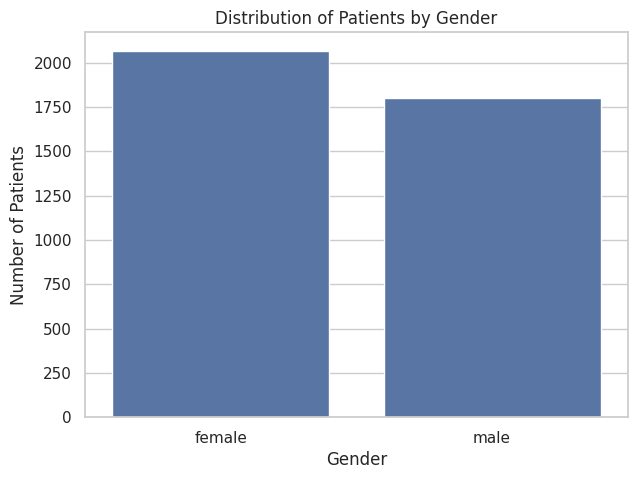

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='gender')

plt.title("Distribution of Patients by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

**Gender Percentage**

In [16]:
gender_percentage = df['gender'].value_counts(normalize=True) * 100

print(gender_percentage)

gender
female    53.436693
male      46.563307
Name: proportion, dtype: float64


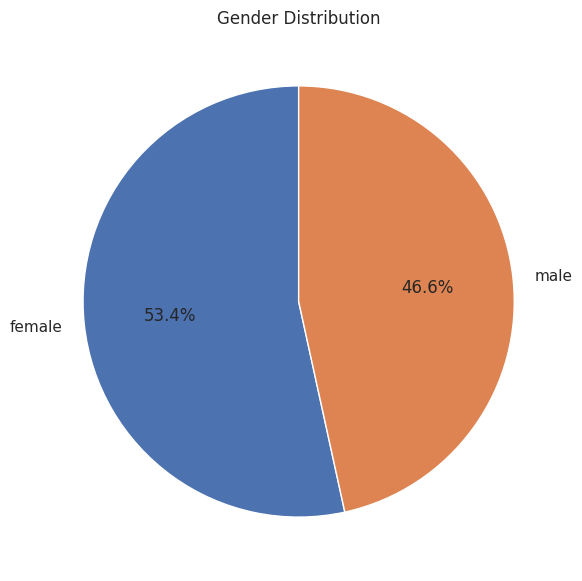

In [17]:
plt.figure(figsize=(7, 7))

df['gender'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Gender Distribution")
plt.ylabel("")

plt.show()

**Age Distribution**

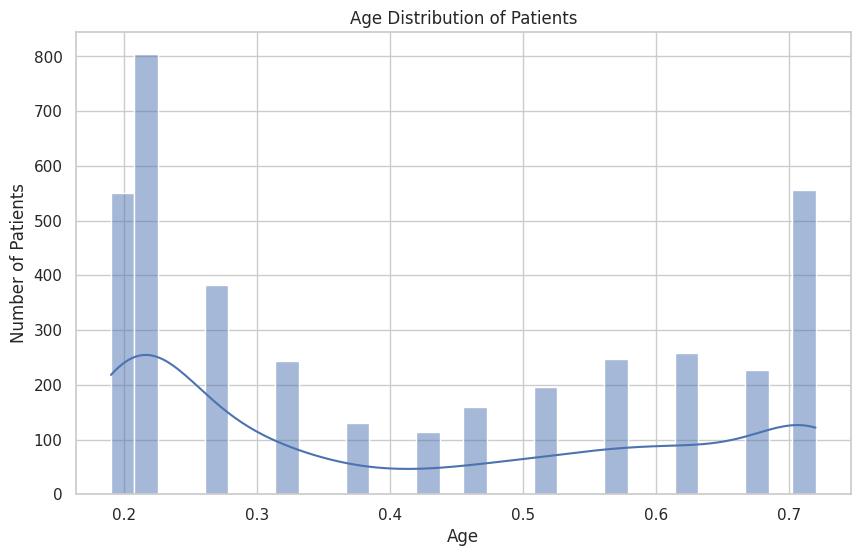

In [18]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='age',
    bins=30,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

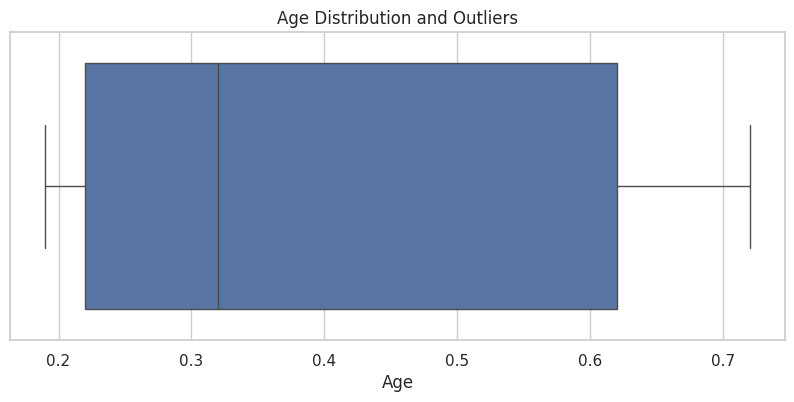

In [19]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['age'])

plt.title("Age Distribution and Outliers")
plt.xlabel("Age")

plt.show()

**Income Distribution**

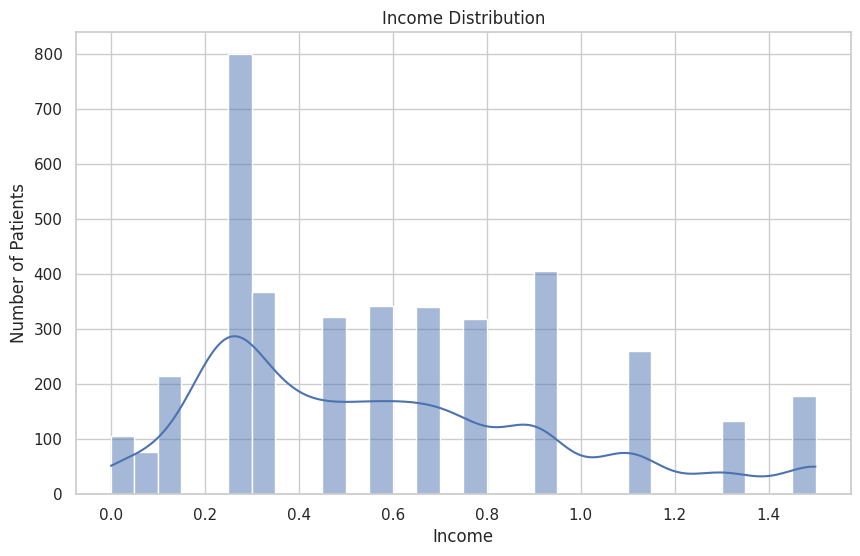

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='income',
    bins=30,
    kde=True
)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Patients")

plt.show()

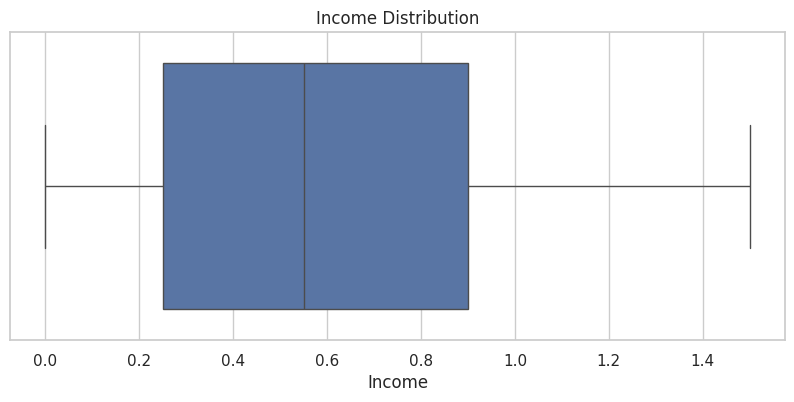

In [21]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['income'])

plt.title("Income Distribution")
plt.xlabel("Income")

plt.show()

**Doctor Visits Distribution**

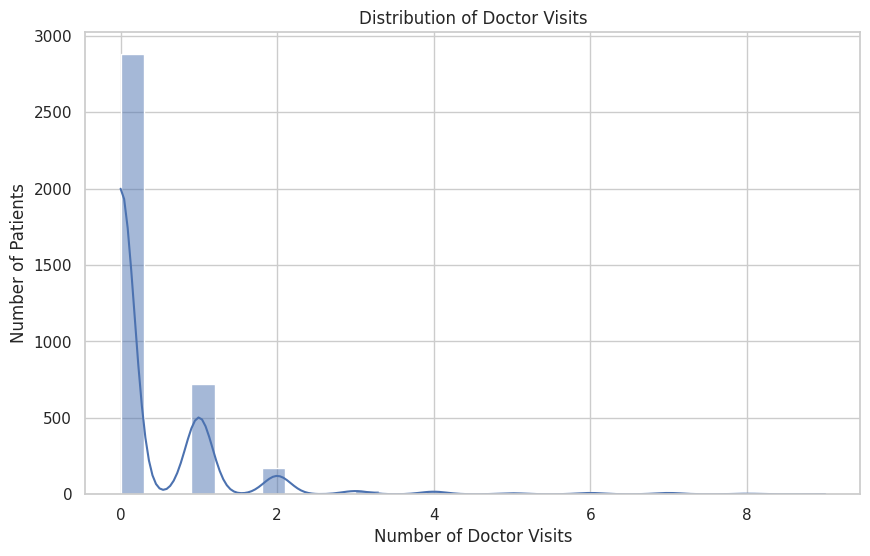

In [22]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='visits',
    bins=30,
    kde=True
)

plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Number of Patients")

plt.show()

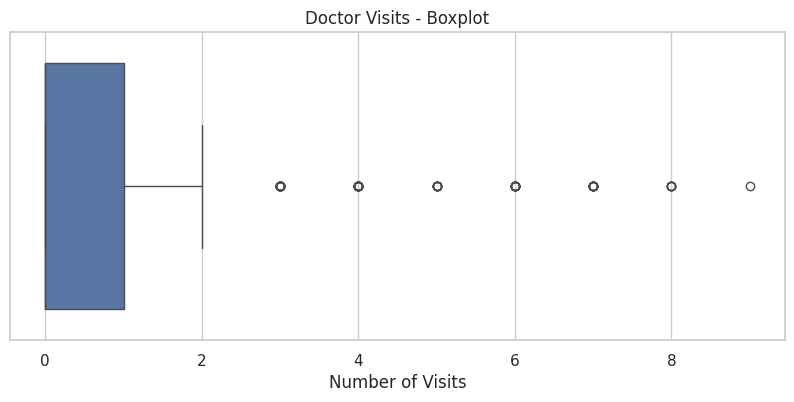

In [23]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['visits'])

plt.title("Doctor Visits - Boxplot")
plt.xlabel("Number of Visits")

plt.show()

**Illness Distribution**

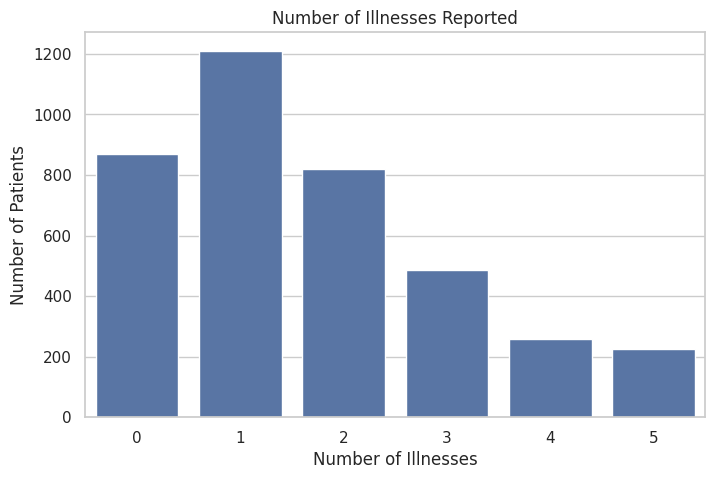

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='illness'
)

plt.title("Number of Illnesses Reported")
plt.xlabel("Number of Illnesses")
plt.ylabel("Number of Patients")

plt.show()

**Health Distribution**

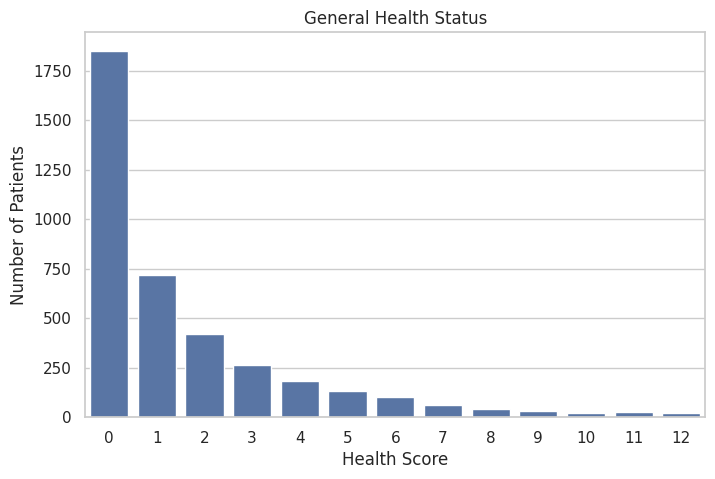

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='health'
)

plt.title("General Health Status")
plt.xlabel("Health Score")
plt.ylabel("Number of Patients")

plt.show()

**Reduced Activity Distribution**

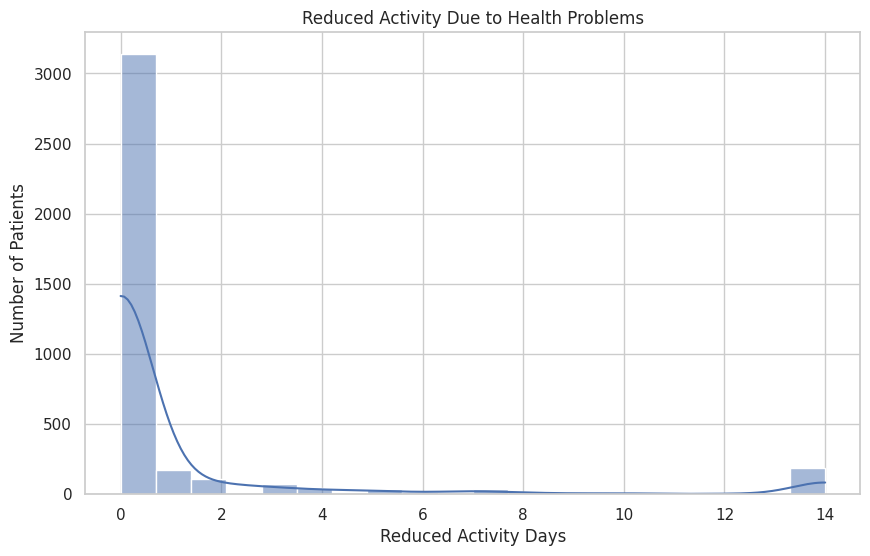

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='reduced',
    bins=20,
    kde=True
)

plt.title("Reduced Activity Due to Health Problems")
plt.xlabel("Reduced Activity Days")
plt.ylabel("Number of Patients")

plt.show()

**Private Insurance Distribution**

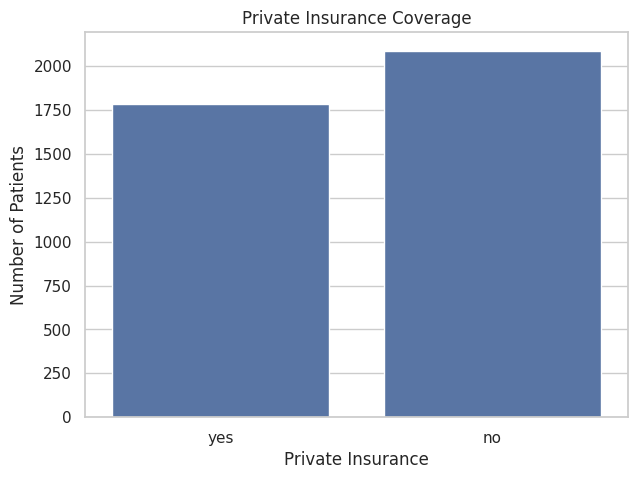

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='private'
)

plt.title("Private Insurance Coverage")
plt.xlabel("Private Insurance")
plt.ylabel("Number of Patients")

plt.show()

**Free/Poor Insurance Distribution**

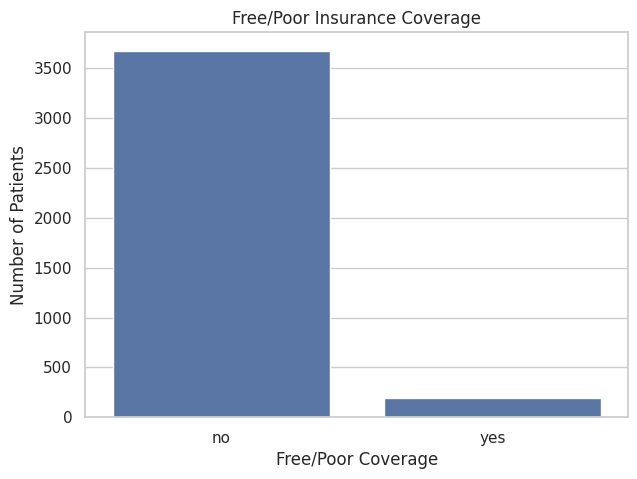

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='freepoor'
)

plt.title("Free/Poor Insurance Coverage")
plt.xlabel("Free/Poor Coverage")
plt.ylabel("Number of Patients")

plt.show()

**Free Repatriation Distribution**

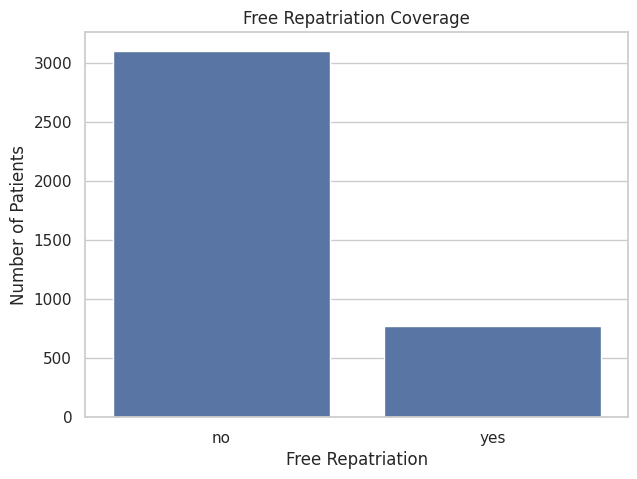

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='freerepat'
)

plt.title("Free Repatriation Coverage")
plt.xlabel("Free Repatriation")
plt.ylabel("Number of Patients")

plt.show()

**Chronic Disease Analysis**

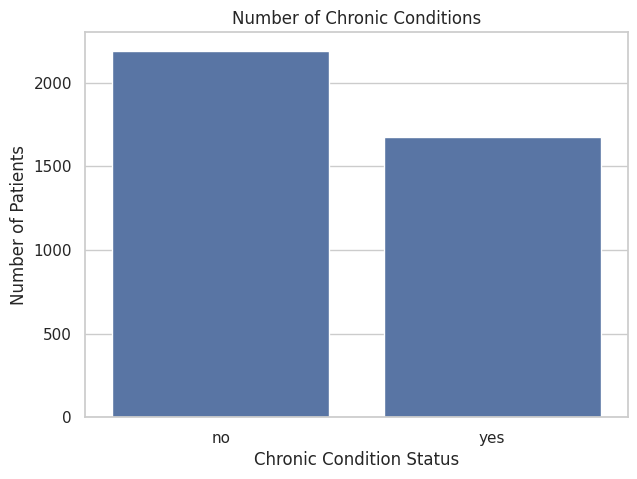

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='nchronic'
)

plt.title("Number of Chronic Conditions")
plt.xlabel("Chronic Condition Status")
plt.ylabel("Number of Patients")

plt.show()

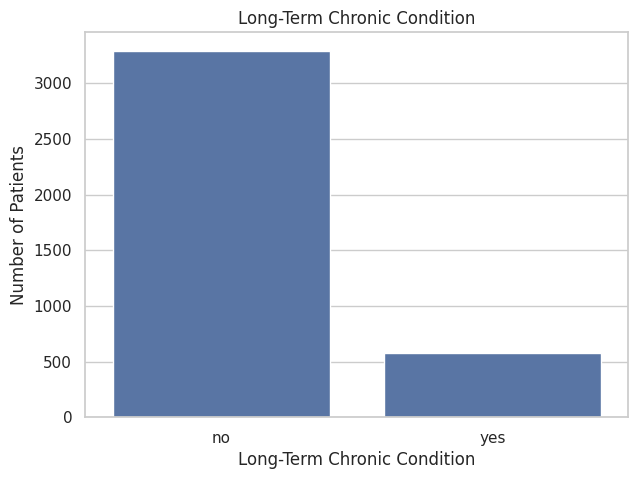

In [31]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='lchronic'
)

plt.title("Long-Term Chronic Condition")
plt.xlabel("Long-Term Chronic Condition")
plt.ylabel("Number of Patients")

plt.show()

**Gender VS Doctoe Visits**

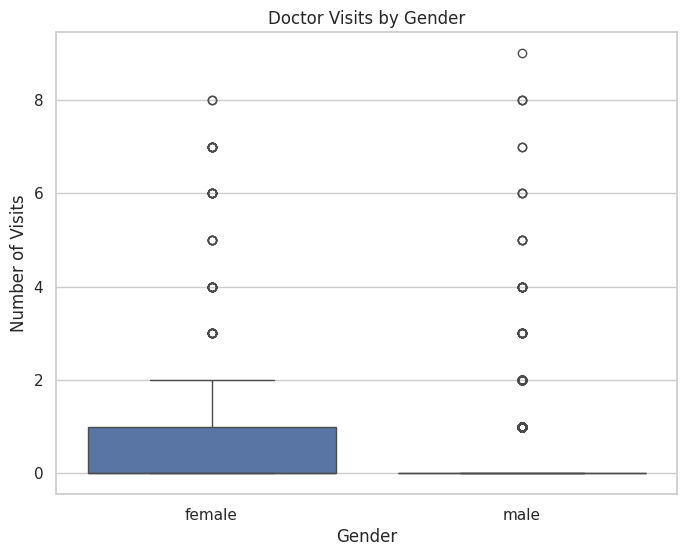

In [32]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='gender',
    y='visits'
)

plt.title("Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Visits")

plt.show()

**Gender VS Average Visits**

In [33]:
gender_visits = df.groupby('gender')['visits'].mean().reset_index()

print(gender_visits)

   gender    visits
0  female  0.449710
1    male  0.319645


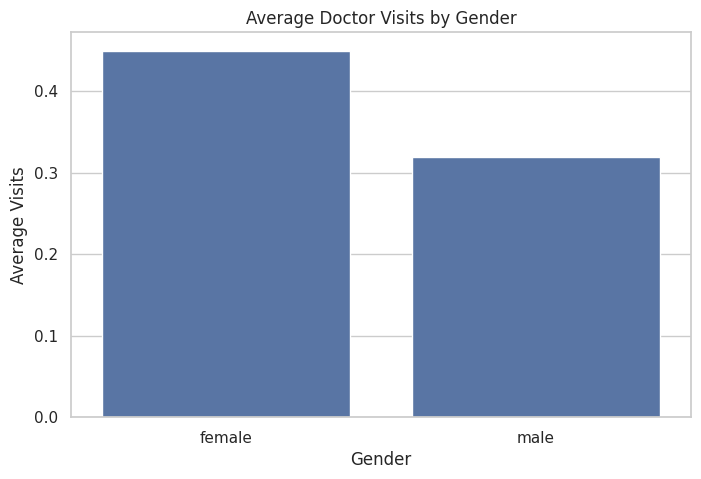

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_visits,
    x='gender',
    y='visits'
)

plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Visits")

plt.show()

**Age VS Doctor Visits**

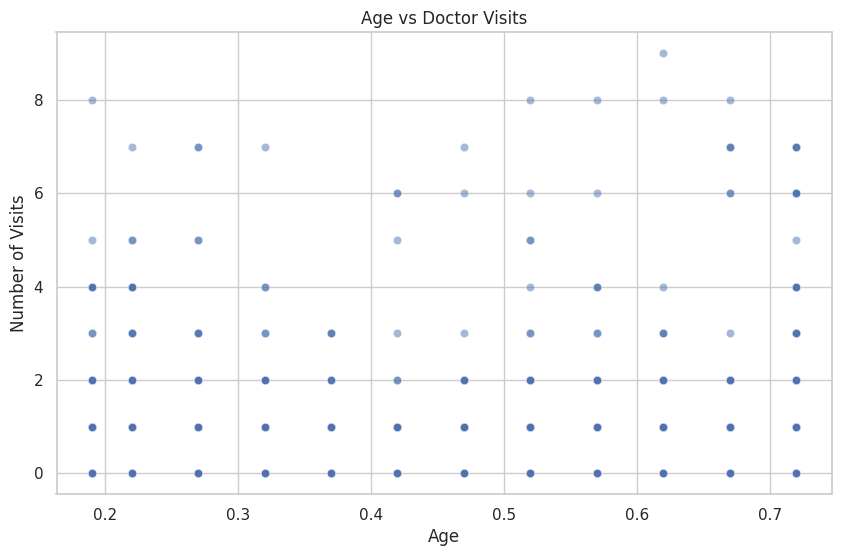

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='age',
    y='visits',
    alpha=0.5
)

plt.title("Age vs Doctor Visits")
plt.xlabel("Age")
plt.ylabel("Number of Visits")

plt.show()

**Income VS Doctor Visits**

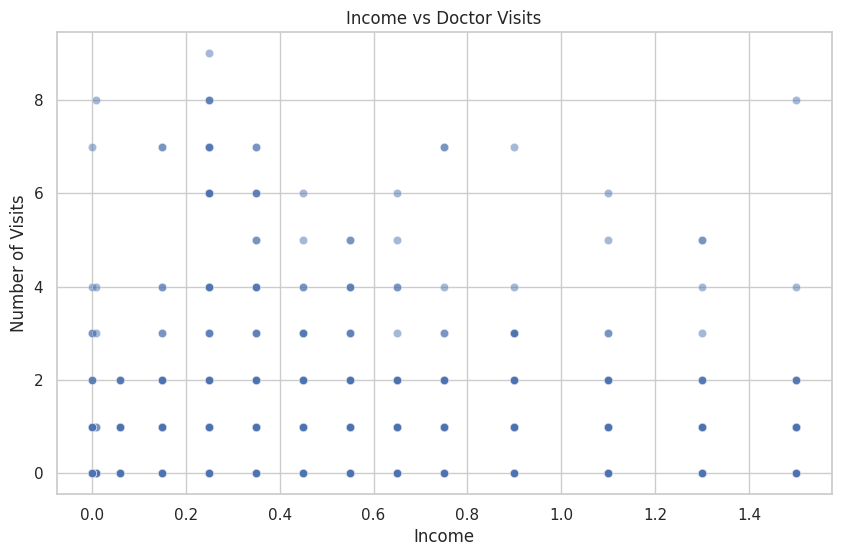

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='income',
    y='visits',
    alpha=0.5
)

plt.title("Income vs Doctor Visits")
plt.xlabel("Income")
plt.ylabel("Number of Visits")

plt.show()

**Illness VS Doctor Visits**

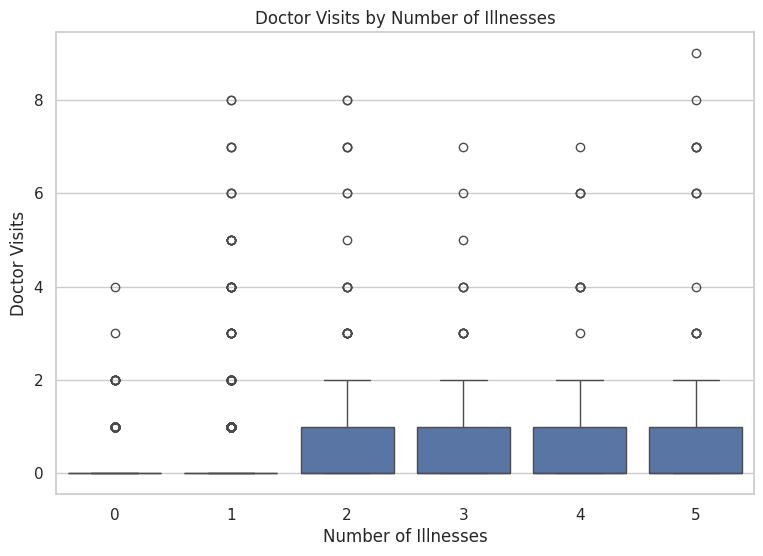

In [37]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='illness',
    y='visits'
)

plt.title("Doctor Visits by Number of Illnesses")
plt.xlabel("Number of Illnesses")
plt.ylabel("Doctor Visits")

plt.show()

**Health VS Doctor Visits**

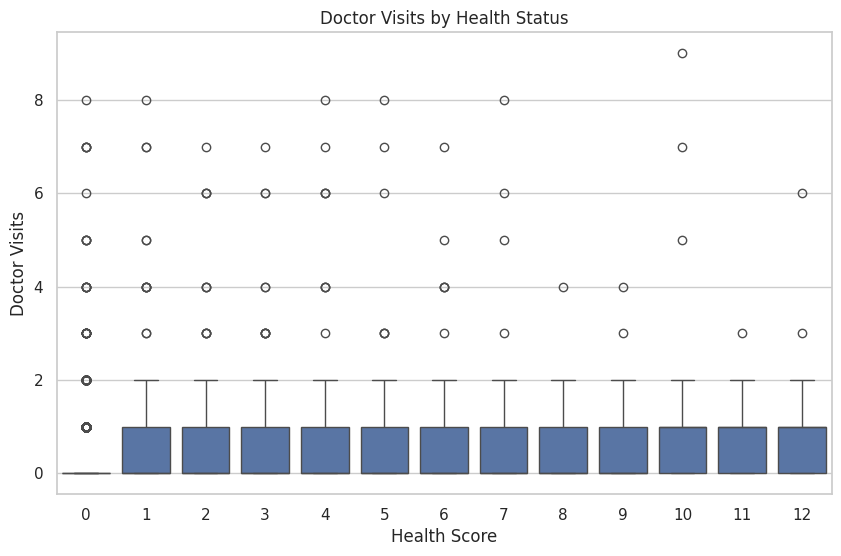

In [38]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='health',
    y='visits'
)

plt.title("Doctor Visits by Health Status")
plt.xlabel("Health Score")
plt.ylabel("Doctor Visits")

plt.show()

**Reduced Activity VS Doctor Visits**

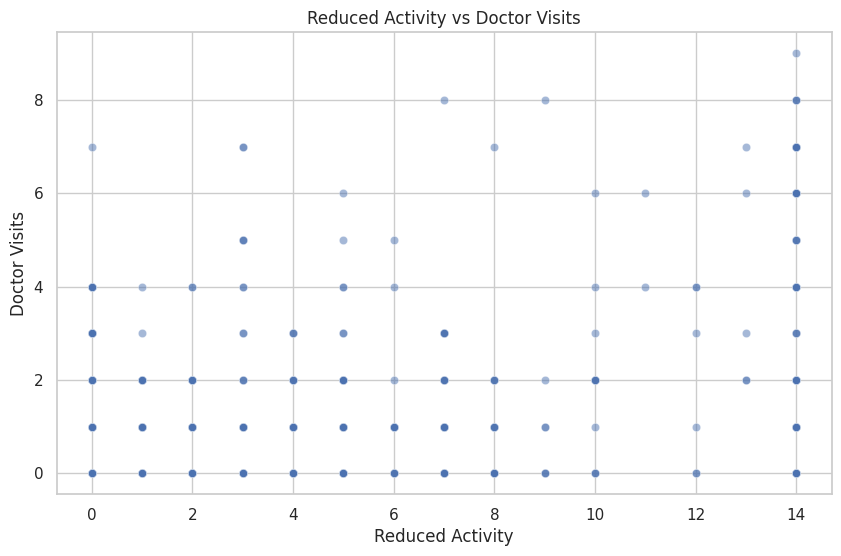

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='reduced',
    y='visits',
    alpha=0.5
)

plt.title("Reduced Activity vs Doctor Visits")
plt.xlabel("Reduced Activity")
plt.ylabel("Doctor Visits")

plt.show()

**Private Insurance VS Doctor Visits**

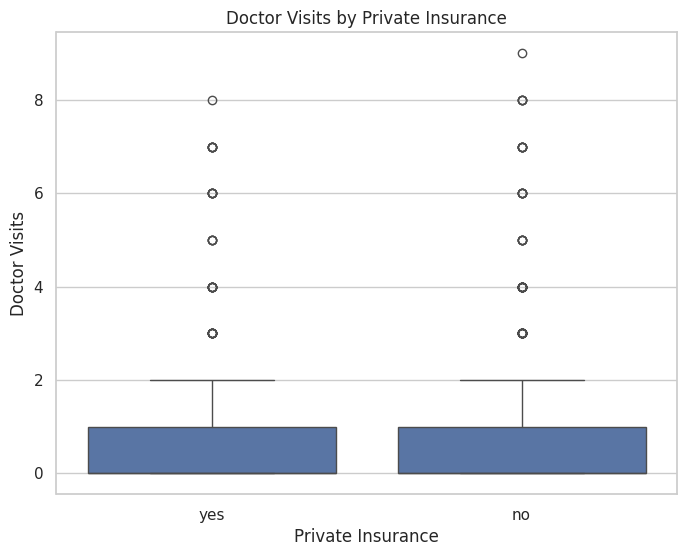

In [40]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='private',
    y='visits'
)

plt.title("Doctor Visits by Private Insurance")
plt.xlabel("Private Insurance")
plt.ylabel("Doctor Visits")

plt.show()

**Chronic Conditon VS Doctor Visits**

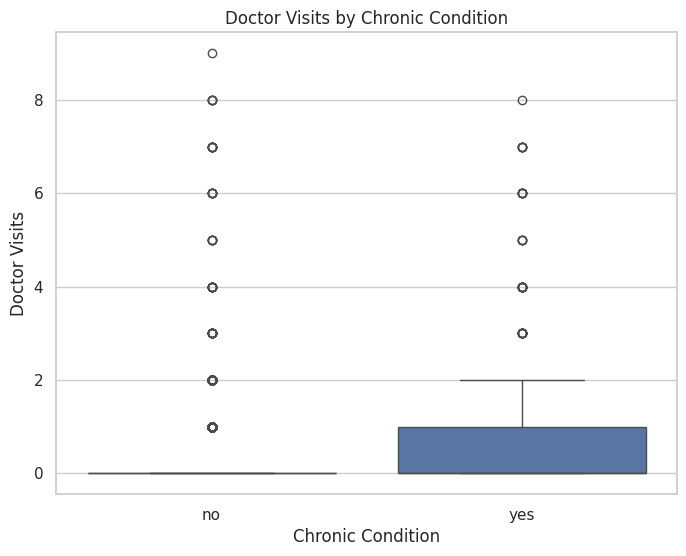

In [41]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='nchronic',
    y='visits'
)

plt.title("Doctor Visits by Chronic Condition")
plt.xlabel("Chronic Condition")
plt.ylabel("Doctor Visits")

plt.show()

**Long Term Chronic Conditon VS Doctor Visits**

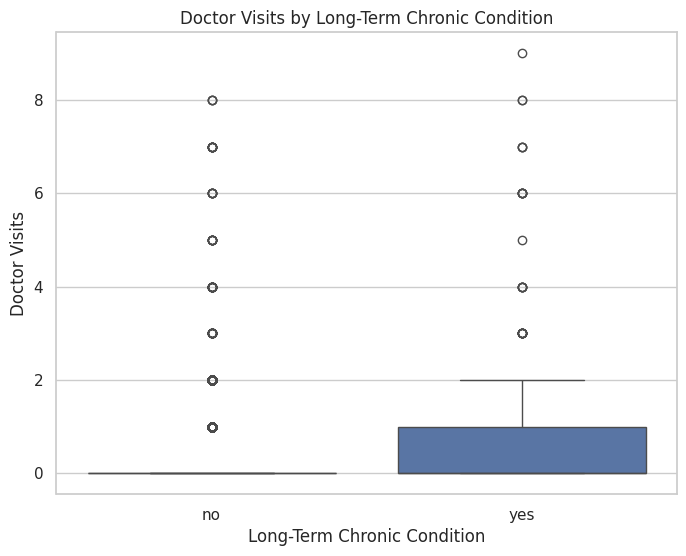

In [42]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='lchronic',
    y='visits'
)

plt.title("Doctor Visits by Long-Term Chronic Condition")
plt.xlabel("Long-Term Chronic Condition")
plt.ylabel("Doctor Visits")

plt.show()

**Average Visits by Age Group**

In [43]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=[
        'Young',
        'Middle-aged',
        'Older',
        'Very Old'
    ]
)

In [44]:
df['age_group'].value_counts()

,count
age_group,
Older,1485
Young,1354
Middle-aged,1031
Very Old,0


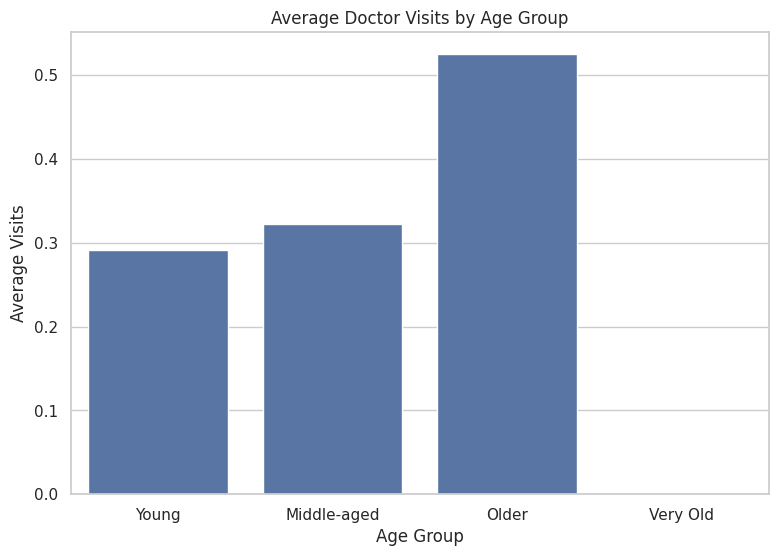

In [45]:
age_visits = df.groupby(
    'age_group',
    observed=True
)['visits'].mean().reset_index()

plt.figure(figsize=(9, 6))

sns.barplot(
    data=age_visits,
    x='age_group',
    y='visits'
)

plt.title("Average Doctor Visits by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Visits")

plt.show()

**Income Group Analysis**

In [46]:
df['income_group'] = pd.cut(
    df['income'],
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=[
        'Low Income',
        'Lower-Middle Income',
        'Upper-Middle Income',
        'High Income'
    ]
)

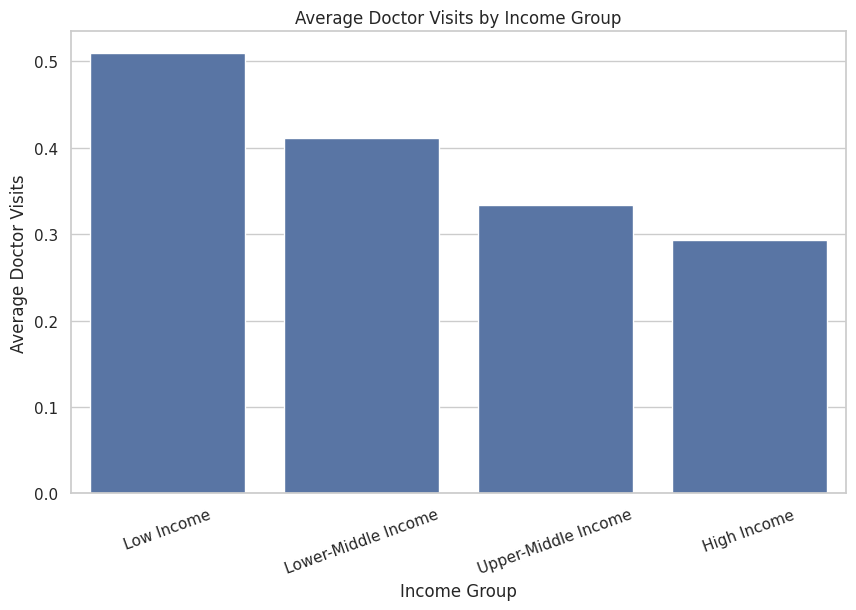

In [47]:
income_visits = df.groupby(
    'income_group',
    observed=True
)['visits'].mean().reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=income_visits,
    x='income_group',
    y='visits'
)

plt.title("Average Doctor Visits by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Average Doctor Visits")
plt.xticks(rotation=20)

plt.show()

**Correlation Matrix and Heatmap**

In [48]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

correlation = df[numeric_cols].corr()

correlation

,visits,age,income,illness,reduced,health
visits,1.000000,0.123836,-0.076916,0.185469,0.403213,0.149304
age,0.123836,1.000000,-0.203979,0.167224,0.105057,0.003812
income,-0.076916,-0.203979,1.000000,-0.134864,-0.053131,-0.096036
illness,0.185469,0.167224,-0.134864,1.000000,0.191833,0.309573
reduced,0.403213,0.105057,-0.053131,0.191833,1.000000,0.246496
health,0.149304,0.003812,-0.096036,0.309573,0.246496,1.000000


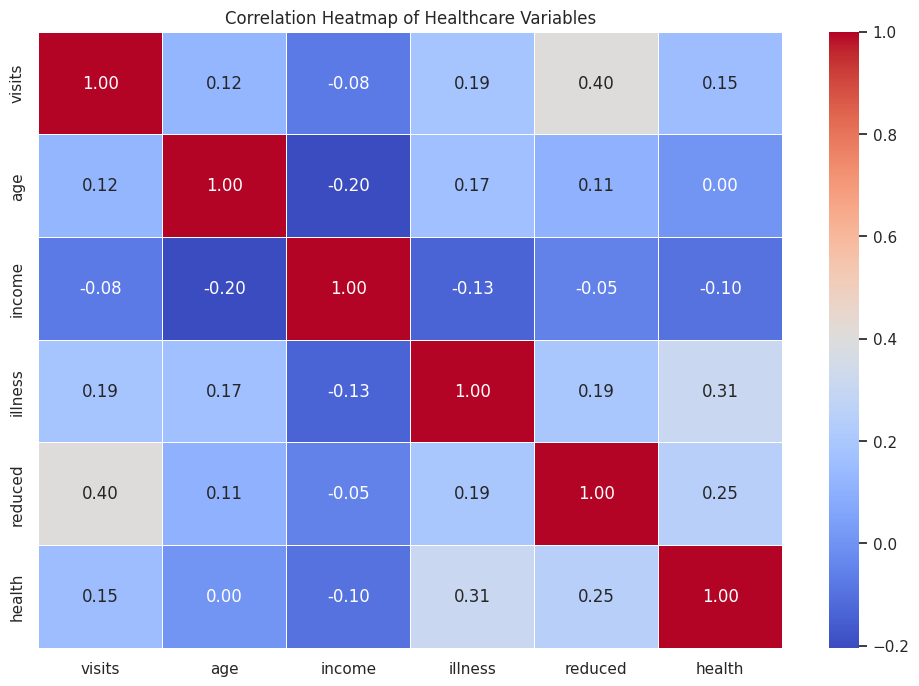

In [49]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Healthcare Variables")

plt.show()

**Correlation With Doctor Visits**

In [50]:
visit_corr = correlation['visits'].sort_values(
    ascending=False
)

print(visit_corr)

visits     1.000000
reduced    0.403213
illness    0.185469
health     0.149304
age        0.123836
income    -0.076916
Name: visits, dtype: float64


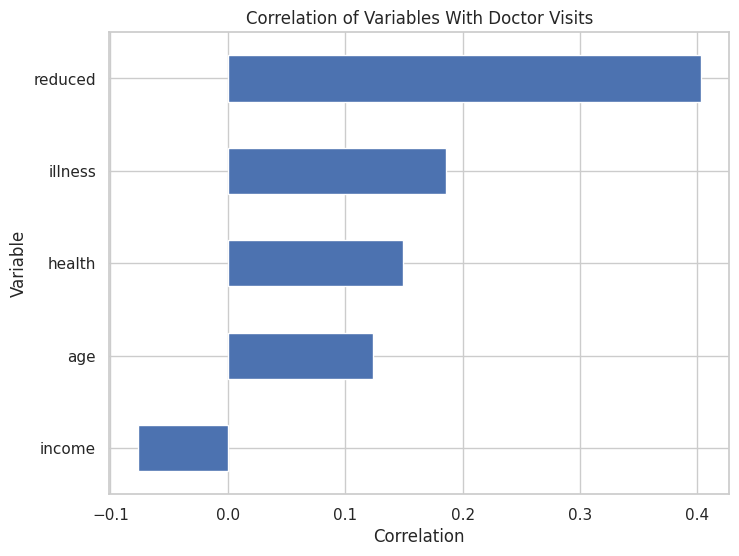

In [51]:
plt.figure(figsize=(8, 6))

visit_corr.drop('visits').sort_values().plot(
    kind='barh'
)

plt.title("Correlation of Variables With Doctor Visits")
plt.xlabel("Correlation")
plt.ylabel("Variable")

plt.show()

**Pairplot**

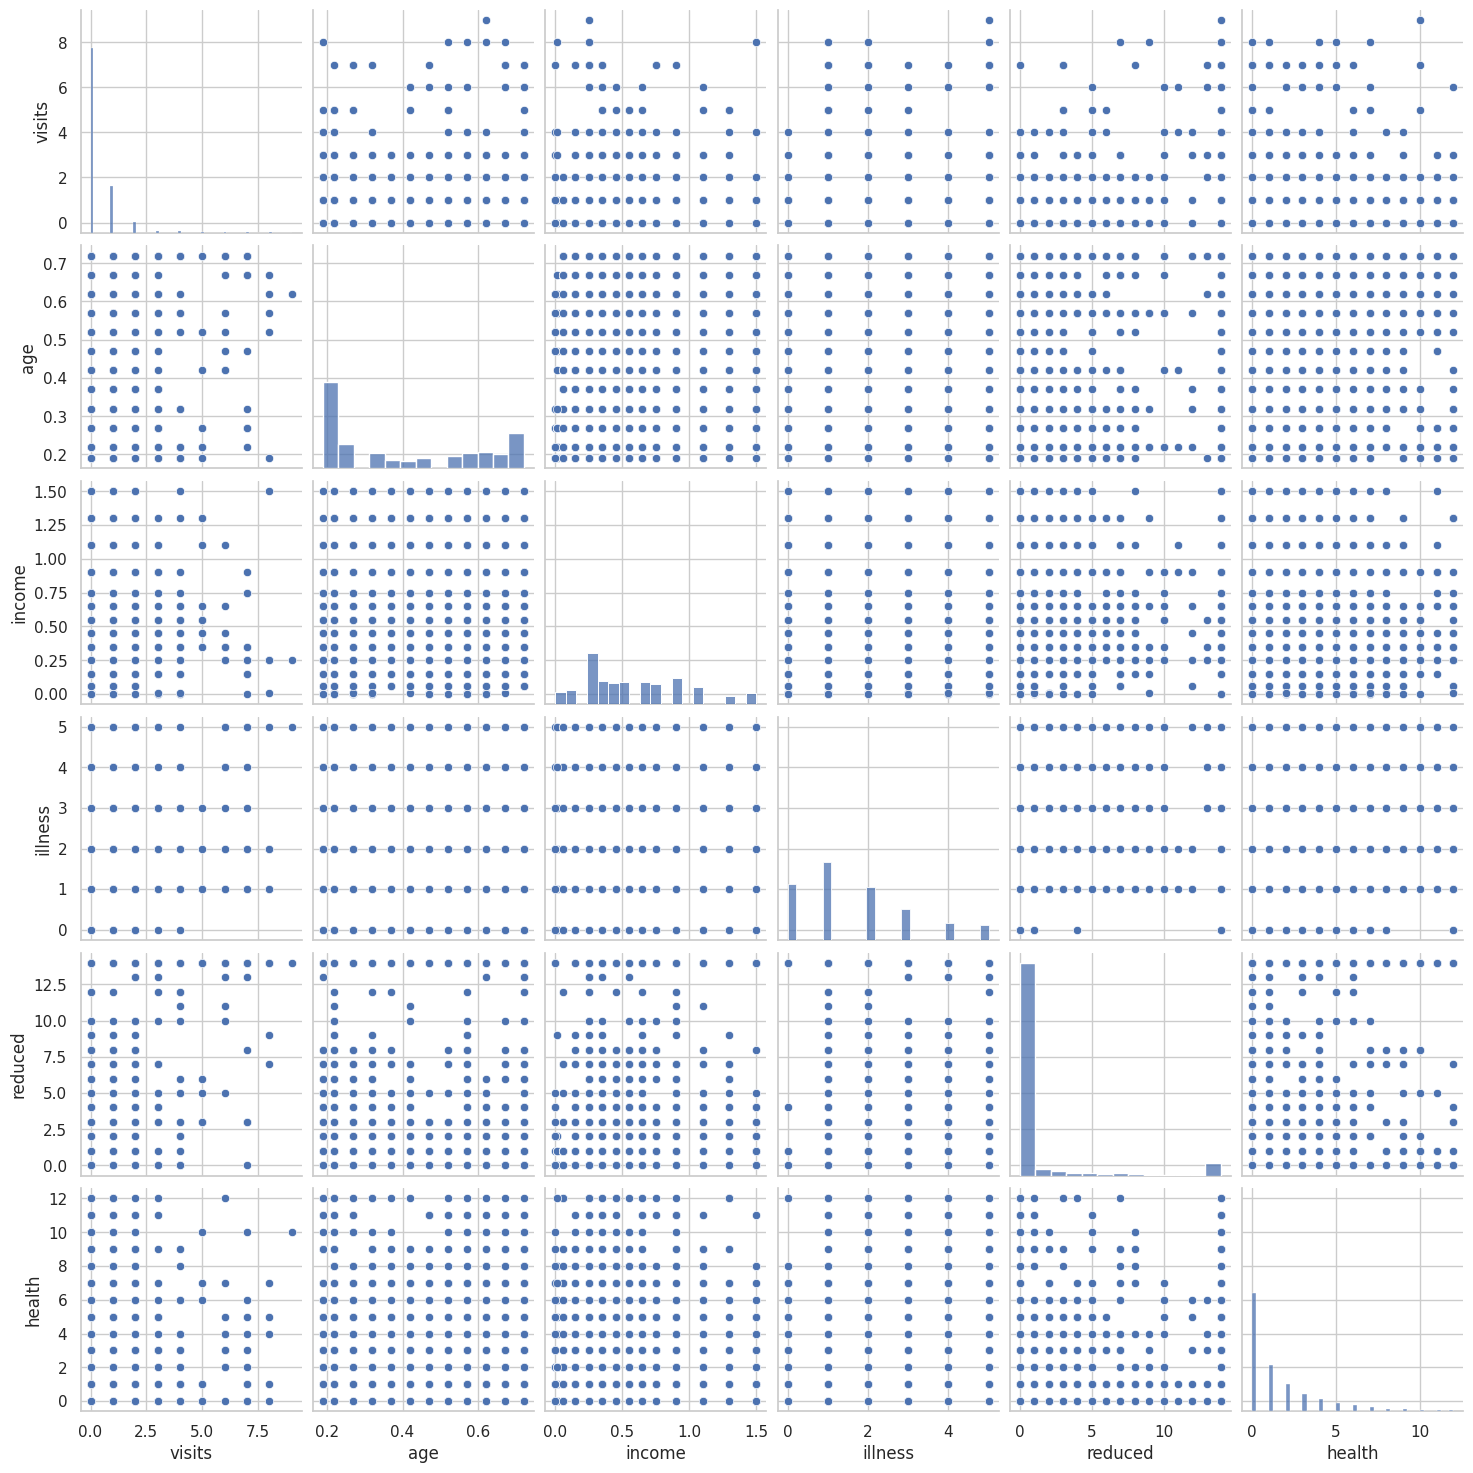

In [52]:
selected_columns = [
    'visits',
    'age',
    'income',
    'illness',
    'reduced',
    'health'
]

sns.pairplot(
    df[selected_columns],
    diag_kind='hist'
)

plt.show()

**Pairplot by Gender**

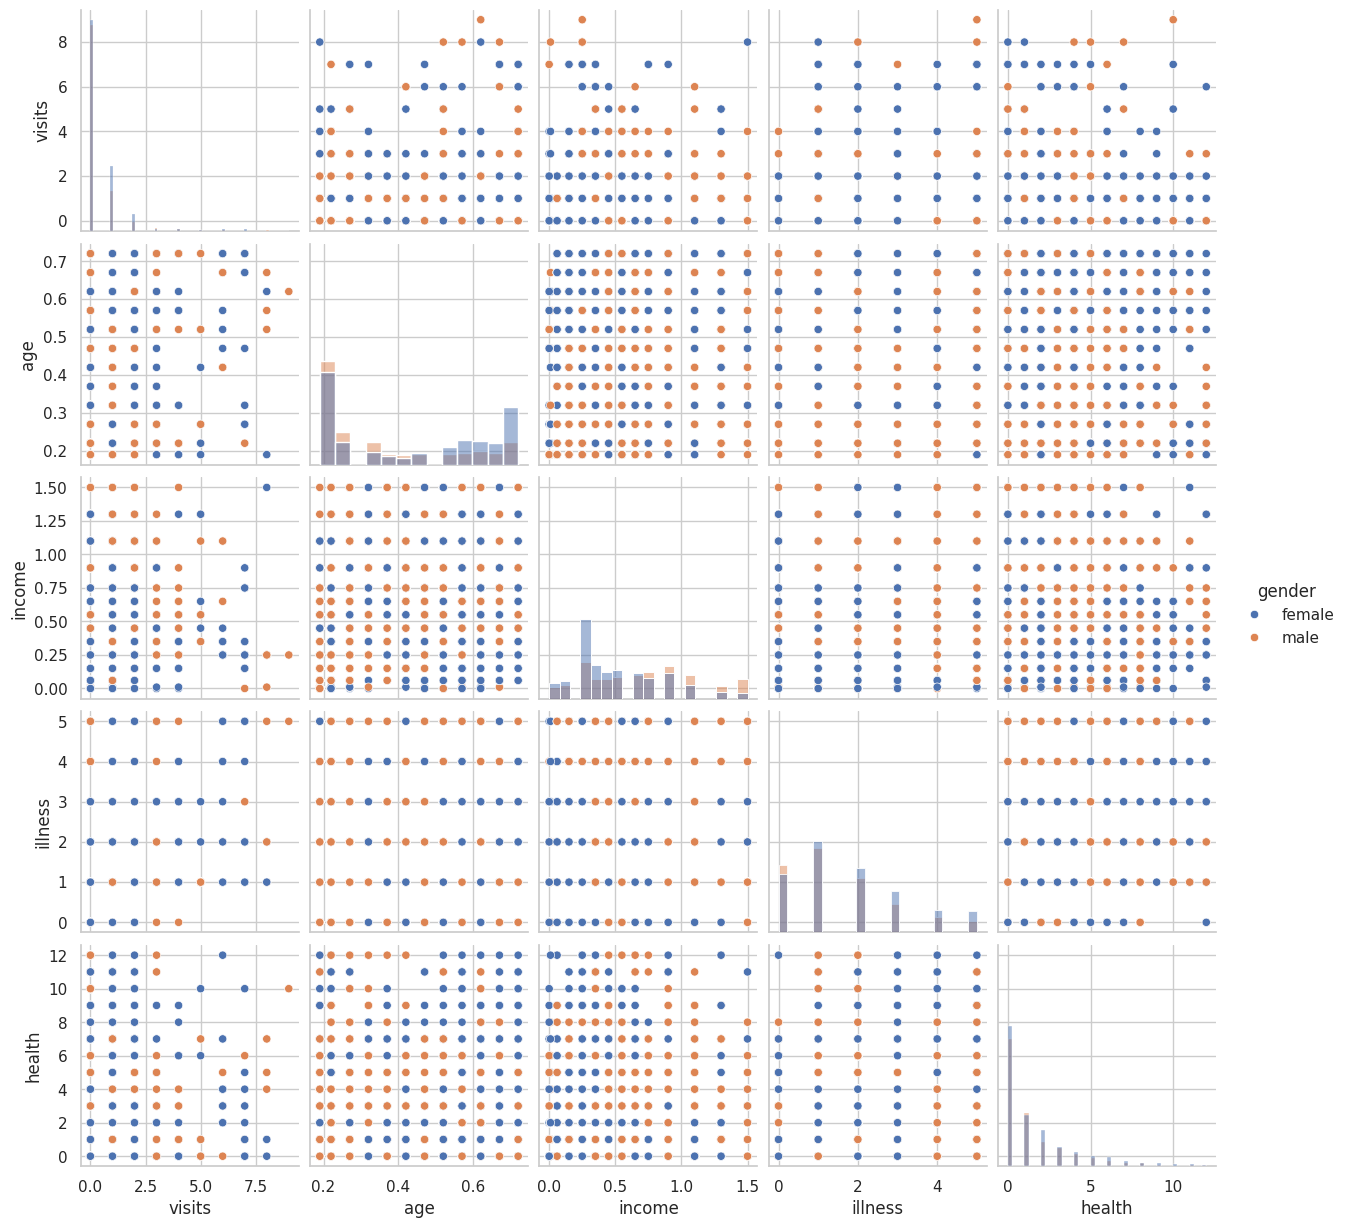

In [53]:
sns.pairplot(
    df[
        [
            'visits',
            'age',
            'income',
            'illness',
            'health',
            'gender'
        ]
    ],
    hue='gender',
    diag_kind='hist'
)

plt.show()

**Docotor Visits by Gender and Health**

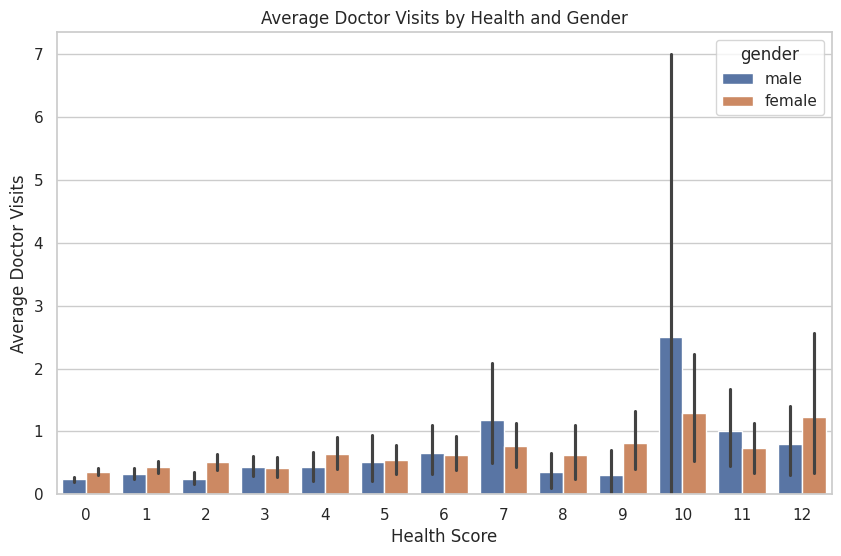

In [54]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='health',
    y='visits',
    hue='gender'
)

plt.title("Average Doctor Visits by Health and Gender")
plt.xlabel("Health Score")
plt.ylabel("Average Doctor Visits")

plt.show()

**Doctor Visits by Gender and Chrnic Condition**

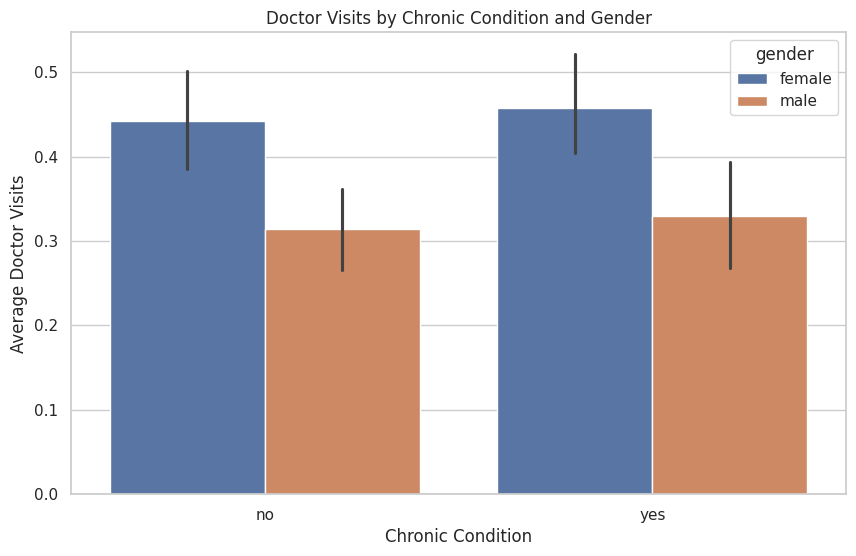

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='nchronic',
    y='visits',
    hue='gender'
)

plt.title("Doctor Visits by Chronic Condition and Gender")
plt.xlabel("Chronic Condition")
plt.ylabel("Average Doctor Visits")

plt.show()

**Doctor Visits by Insurance and Gender**

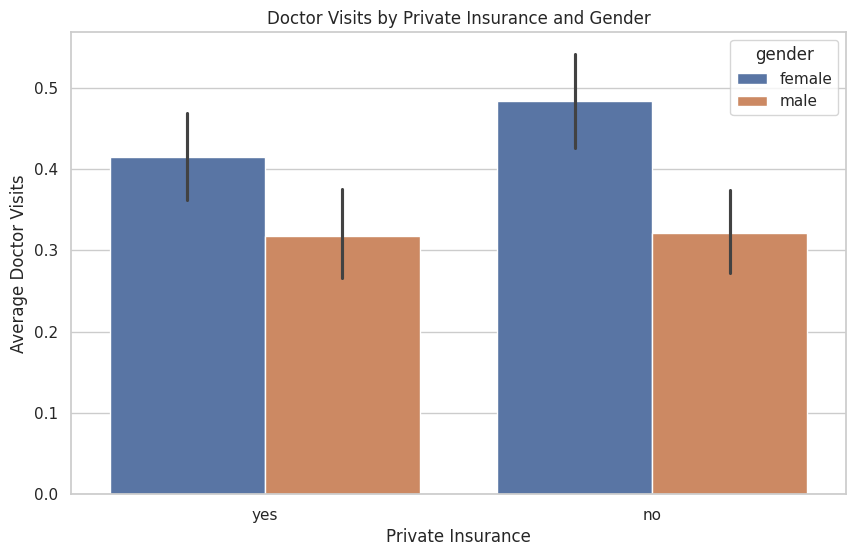

In [56]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='private',
    y='visits',
    hue='gender'
)

plt.title("Doctor Visits by Private Insurance and Gender")
plt.xlabel("Private Insurance")
plt.ylabel("Average Doctor Visits")

plt.show()

**Income VS Health**

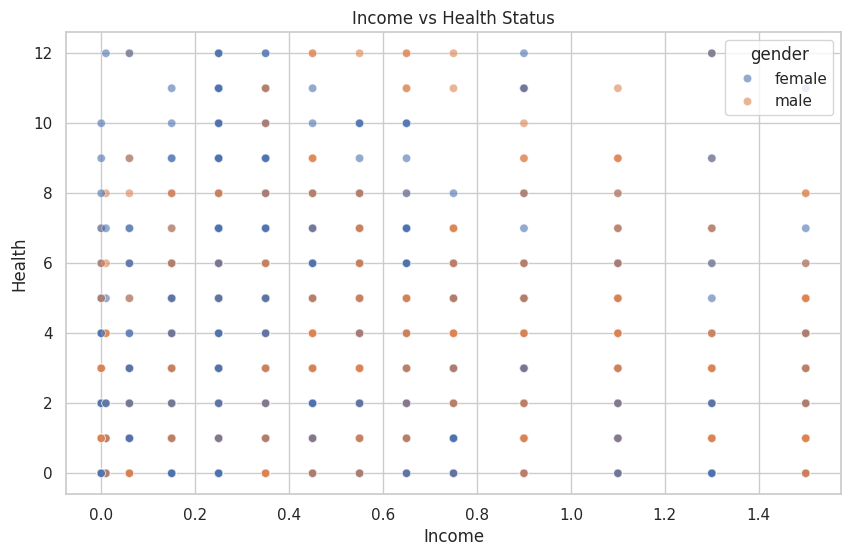

In [57]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='income',
    y='health',
    hue='gender',
    alpha=0.6
)

plt.title("Income vs Health Status")
plt.xlabel("Income")
plt.ylabel("Health")

plt.show()

**Illness VS Reduced Activity**

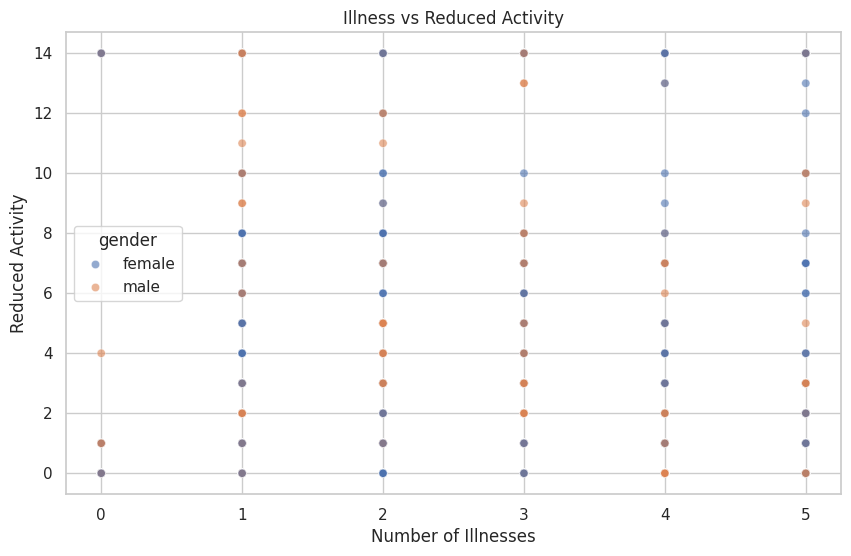

In [58]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='illness',
    y='reduced',
    hue='gender',
    alpha=0.6
)

plt.title("Illness vs Reduced Activity")
plt.xlabel("Number of Illnesses")
plt.ylabel("Reduced Activity")

plt.show()

**Health VS Income Heatmap**

In [59]:
income_health = pd.crosstab(
    df['income_group'],
    df['health']
)

income_health

health,0,1,2,3,4,5,6,7,8,9,10,11,12
income_group,,,,,,,,,,,,,
Low Income,470,218,138,82,53,46,39,27,16,15,8,8,7
Lower-Middle Income,321,117,82,42,47,27,15,9,9,7,5,6,4
Upper-Middle Income,512,190,111,64,33,26,28,15,8,2,6,3,4
High Income,202,78,36,29,24,16,8,1,3,2,1,5,1


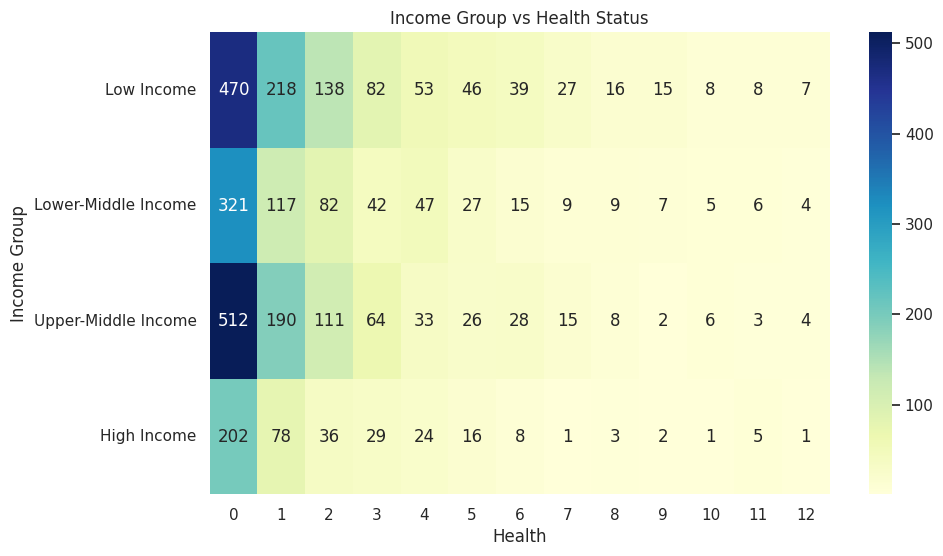

In [60]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    income_health,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Income Group vs Health Status")
plt.xlabel("Health")
plt.ylabel("Income Group")

plt.show()

**Gender VS Health Heatmap**

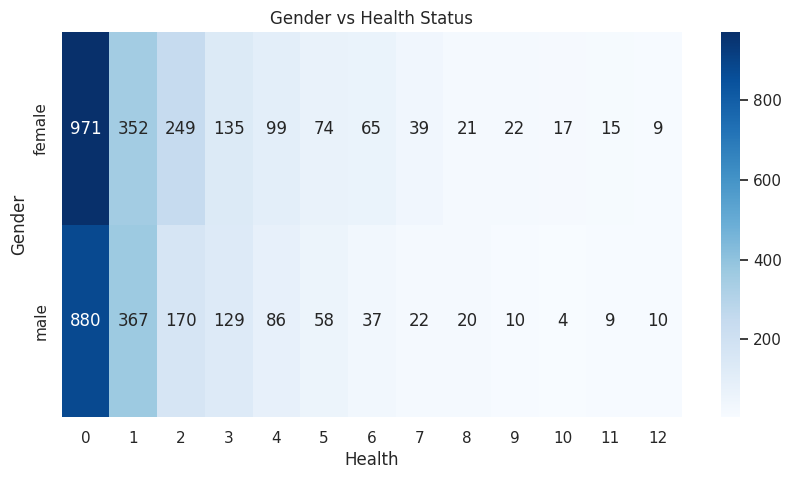

In [61]:
gender_health = pd.crosstab(
    df['gender'],
    df['health']
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    gender_health,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Gender vs Health Status")
plt.xlabel("Health")
plt.ylabel("Gender")

plt.show()

**Gender VS Chronic Condition Heatmap**

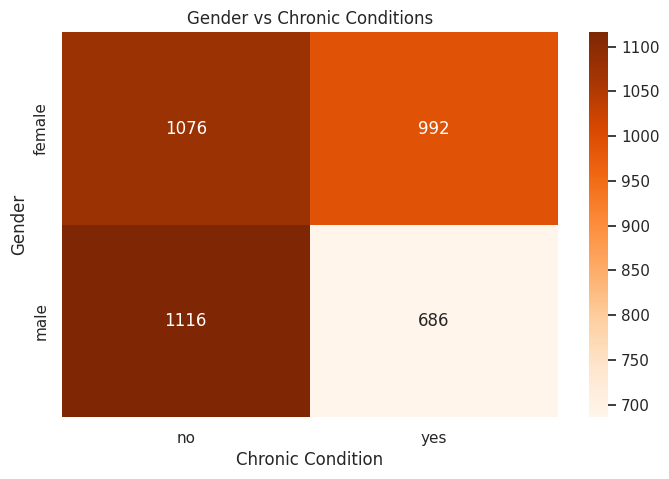

In [62]:
gender_chronic = pd.crosstab(
    df['gender'],
    df['nchronic']
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    gender_chronic,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title("Gender vs Chronic Conditions")
plt.xlabel("Chronic Condition")
plt.ylabel("Gender")

plt.show()

**Insurance VS Chronic Condition Heatmap**

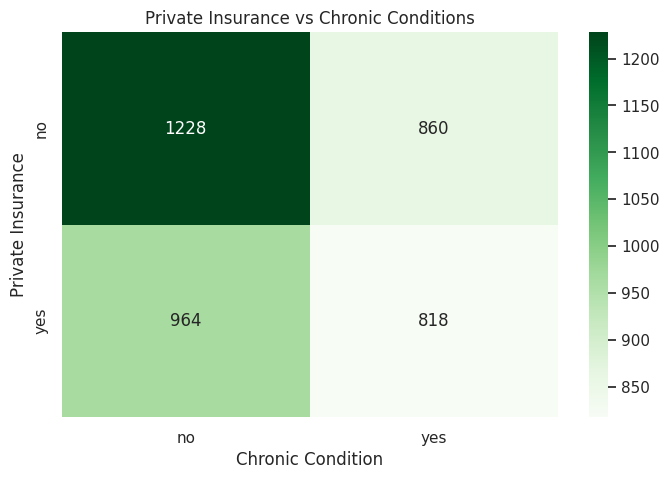

In [63]:
insurance_chronic = pd.crosstab(
    df['private'],
    df['nchronic']
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    insurance_chronic,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Private Insurance vs Chronic Conditions")
plt.xlabel("Chronic Condition")
plt.ylabel("Private Insurance")

plt.show()

**Health vs Chronic Condition Heatmap**

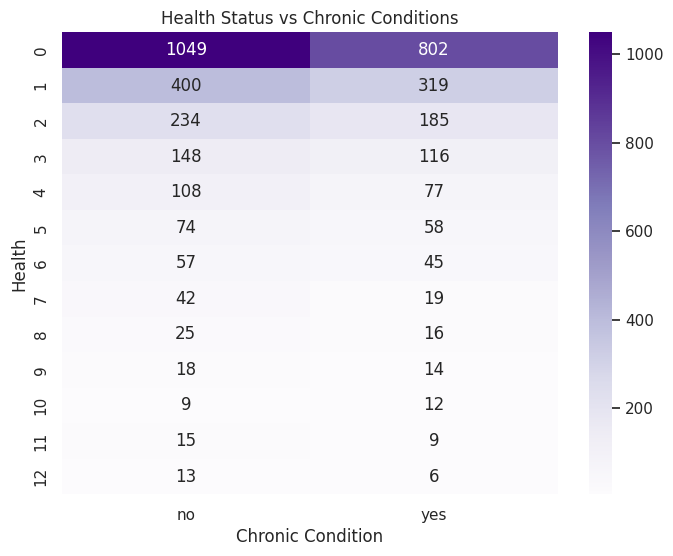

In [64]:
health_chronic = pd.crosstab(
    df['health'],
    df['nchronic']
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    health_chronic,
    annot=True,
    fmt='d',
    cmap='Purples'
)

plt.title("Health Status vs Chronic Conditions")
plt.xlabel("Chronic Condition")
plt.ylabel("Health")

plt.show()

**Average Visits Heatmap**

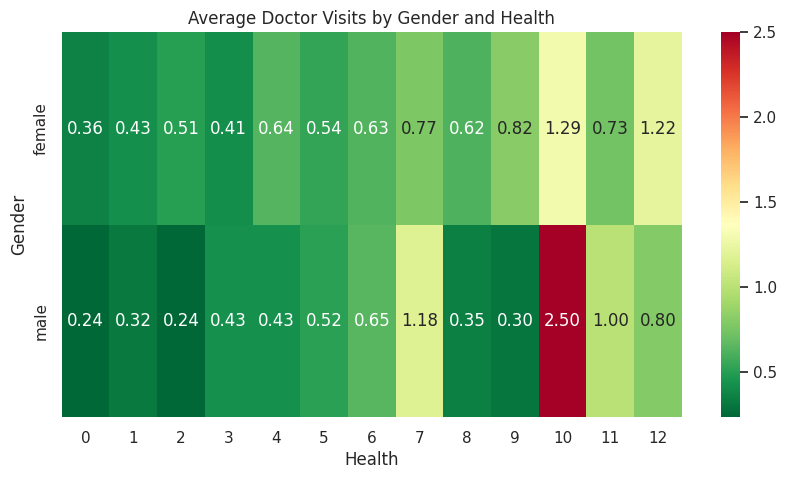

In [65]:
visit_heatmap = pd.pivot_table(
    df,
    values='visits',
    index='gender',
    columns='health',
    aggfunc='mean'
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    visit_heatmap,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r'
)

plt.title("Average Doctor Visits by Gender and Health")
plt.xlabel("Health")
plt.ylabel("Gender")

plt.show()

**Age Group vs Health Heatmap**

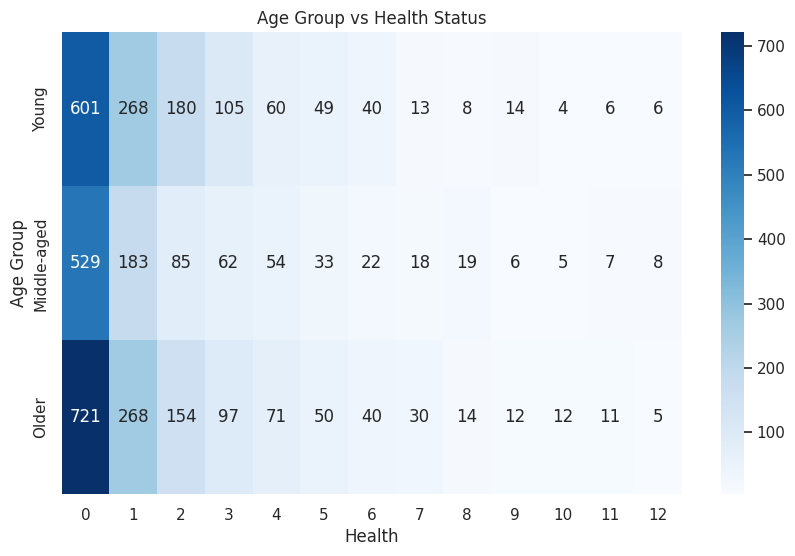

In [66]:
age_health = pd.crosstab(
    df['age_group'],
    df['health']
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    age_health,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Age Group vs Health Status")
plt.xlabel("Health")
plt.ylabel("Age Group")

plt.show()

**Age Group vs Chronic Condition**

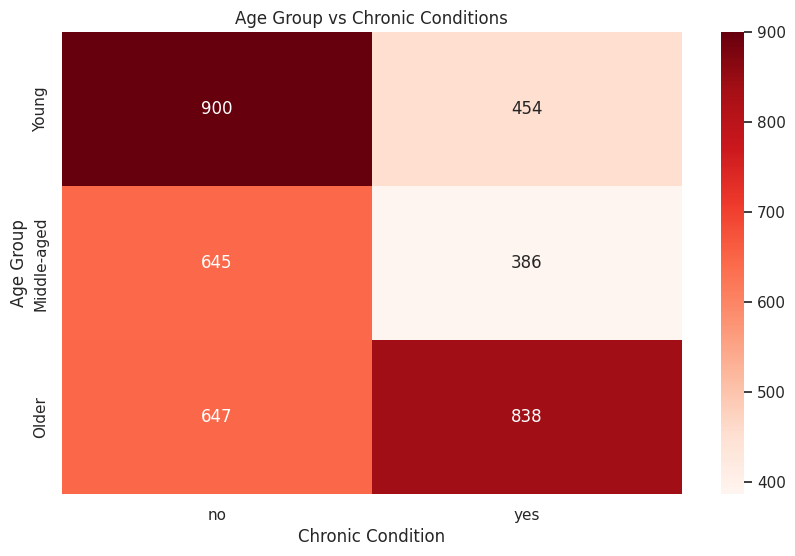

In [67]:
age_chronic = pd.crosstab(
    df['age_group'],
    df['nchronic']
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    age_chronic,
    annot=True,
    fmt='d',
    cmap='Reds'
)

plt.title("Age Group vs Chronic Conditions")
plt.xlabel("Chronic Condition")
plt.ylabel("Age Group")

plt.show()

**Top Doctor Visit Groups**

In [68]:
visit_counts = df['visits'].value_counts().sort_index()

print(visit_counts)

visits
0    2880
1     724
2     173
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64


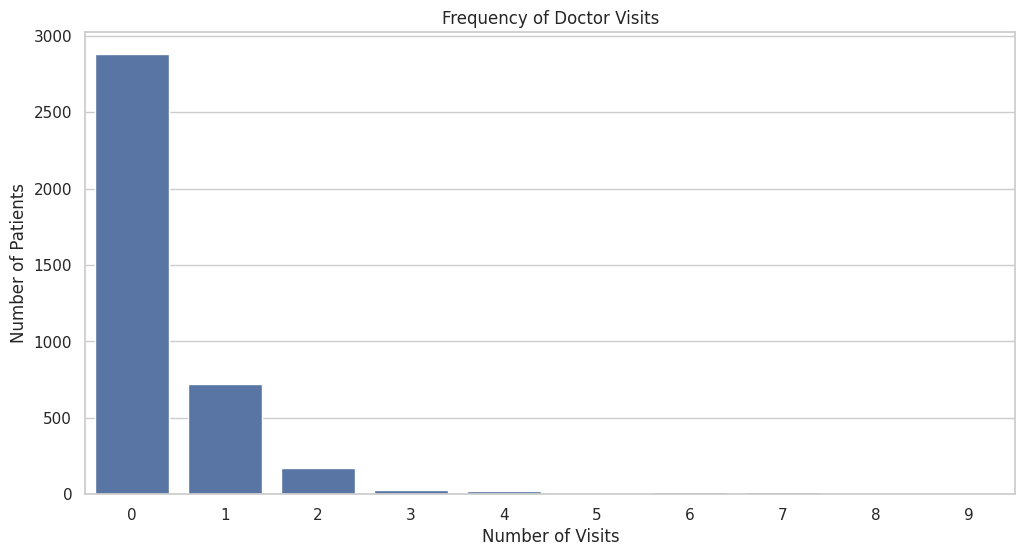

In [69]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=visit_counts.index,
    y=visit_counts.values
)

plt.title("Frequency of Doctor Visits")
plt.xlabel("Number of Visits")
plt.ylabel("Number of Patients")

plt.show()

**Average Healthcare Utilization by Gender**

In [70]:
summary_gender = df.groupby('gender').agg({
    'visits': 'mean',
    'illness': 'mean',
    'reduced': 'mean',
    'health': 'mean'
})

summary_gender

,visits,illness,reduced,health
gender,,,,
female,0.449710,1.805609,1.267892,1.689072
male,0.319645,1.515538,1.018313,1.450055


**Comprehensive Group Analysis**

In [71]:
summary = df.groupby('gender').agg(
    Total_Patients=('gender', 'count'),
    Average_Visits=('visits', 'mean'),
    Average_Age=('age', 'mean'),
    Average_Income=('income', 'mean'),
    Average_Illness=('illness', 'mean'),
    Average_Reduced=('reduced', 'mean'),
    Average_Health=('health', 'mean')
)

summary

,Total_Patients,Average_Visits,Average_Age,Average_Income,Average_Illness,Average_Reduced,Average_Health
gender,,,,,,,
female,2068,0.449710,0.448956,0.502321,1.805609,1.267892,1.689072
male,1802,0.319645,0.366931,0.674623,1.515538,1.018313,1.450055


**Chronic Condition Statistics**

In [72]:
chronic_summary = df.groupby('nchronic').agg(
    Patients=('nchronic', 'count'),
    Average_Visits=('visits', 'mean'),
    Average_Illness=('illness', 'mean'),
    Average_Health=('health', 'mean')
)

chronic_summary

,Patients,Average_Visits,Average_Illness,Average_Health
nchronic,,,,
no,2192,0.376825,1.445712,1.607208
yes,1678,0.405244,1.964243,1.539333


**Insurance Analysis**

In [73]:
insurance_summary = df.groupby('private').agg(
    Patients=('private', 'count'),
    Average_Visits=('visits', 'mean'),
    Average_Income=('income', 'mean'),
    Average_Health=('health', 'mean'),
    Average_Illness=('illness', 'mean')
)

insurance_summary

,Patients,Average_Visits,Average_Income,Average_Health,Average_Illness
private,,,,,
no,2088,0.403257,0.490967,1.742816,1.745211
yes,1782,0.372615,0.689860,1.384400,1.583053


**High Doctor-Visit Patients**

In [75]:
visit_threshold = df['visits'].quantile(0.90)

print("90th percentile:", visit_threshold)

90th percentile: 1.0


In [76]:
high_visit_patients = df[
    df['visits'] >= visit_threshold
]

print(
    "Number of high-visit patients:",
    len(high_visit_patients)
)

high_visit_patients.head()

Number of high-visit patients: 990


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,age_group,income_group
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no,Young,Upper-Middle Income
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no,Young,Lower-Middle Income
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no,Young,High Income
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no,Young,Low Income
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no,Young,Lower-Middle Income


**Compare High-Visit vs Normal Patients**

In [77]:
df['visit_category'] = np.where(
    df['visits'] >= visit_threshold,
    'High Visits',
    'Normal Visits'
)

df['visit_category'].value_counts()

,count
visit_category,
Normal Visits,2880
High Visits,990


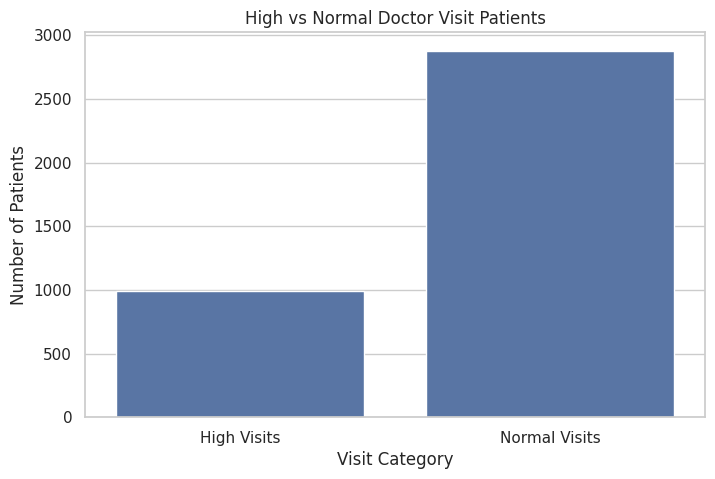

In [78]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='visit_category'
)

plt.title("High vs Normal Doctor Visit Patients")
plt.xlabel("Visit Category")
plt.ylabel("Number of Patients")

plt.show()

**High Visits by Gender**

In [79]:
high_visit_gender = pd.crosstab(
    df['gender'],
    df['visit_category'],
    normalize='index'
) * 100

high_visit_gender

visit_category,High Visits,Normal Visits
gender,,
female,29.642166,70.357834
male,20.921199,79.078801


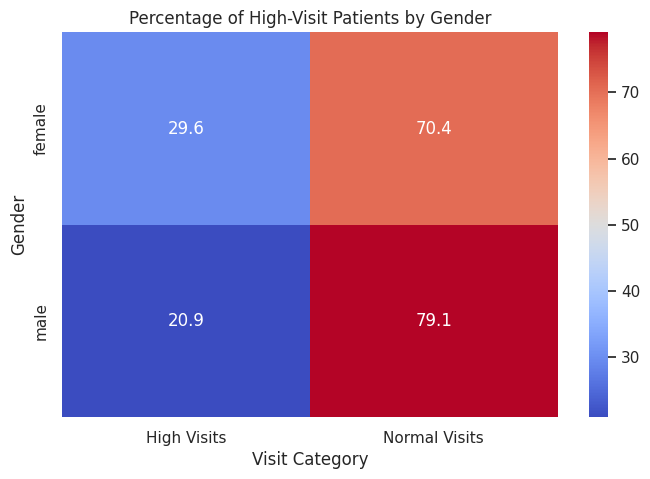

In [80]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    high_visit_gender,
    annot=True,
    fmt='.1f',
    cmap='coolwarm'
)

plt.title("Percentage of High-Visit Patients by Gender")
plt.xlabel("Visit Category")
plt.ylabel("Gender")

plt.show()

**High Visits vs Chronic Condition**

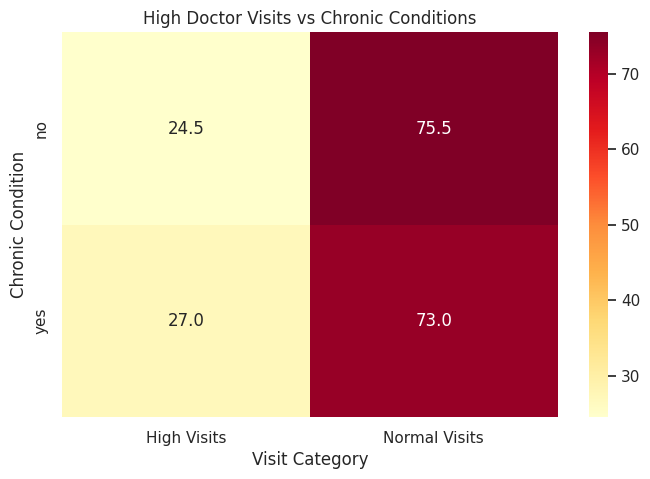

In [81]:
high_chronic = pd.crosstab(
    df['nchronic'],
    df['visit_category'],
    normalize='index'
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    high_chronic,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)

plt.title("High Doctor Visits vs Chronic Conditions")
plt.xlabel("Visit Category")
plt.ylabel("Chronic Condition")

plt.show()

**High Visits vs Health**

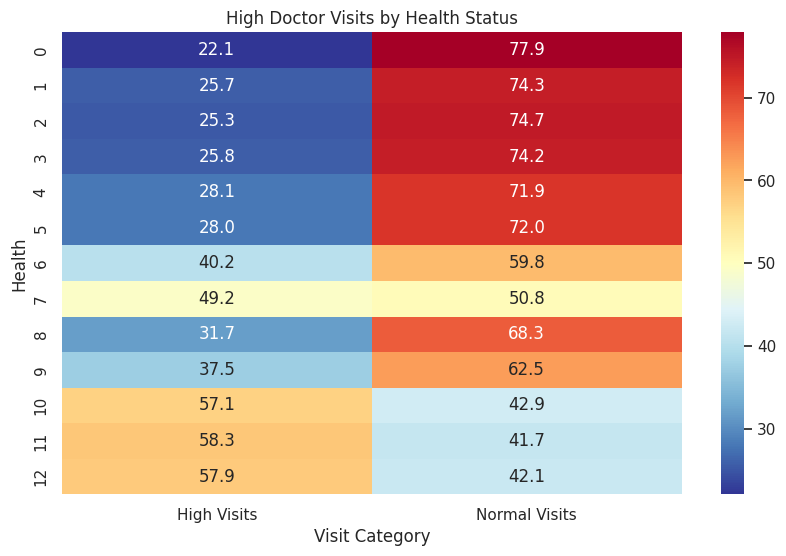

In [82]:
high_health = pd.crosstab(
    df['health'],
    df['visit_category'],
    normalize='index'
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    high_health,
    annot=True,
    fmt='.1f',
    cmap='RdYlBu_r'
)

plt.title("High Doctor Visits by Health Status")
plt.xlabel("Visit Category")
plt.ylabel("Health")

plt.show()

**Distribution of All Numerical Variables**

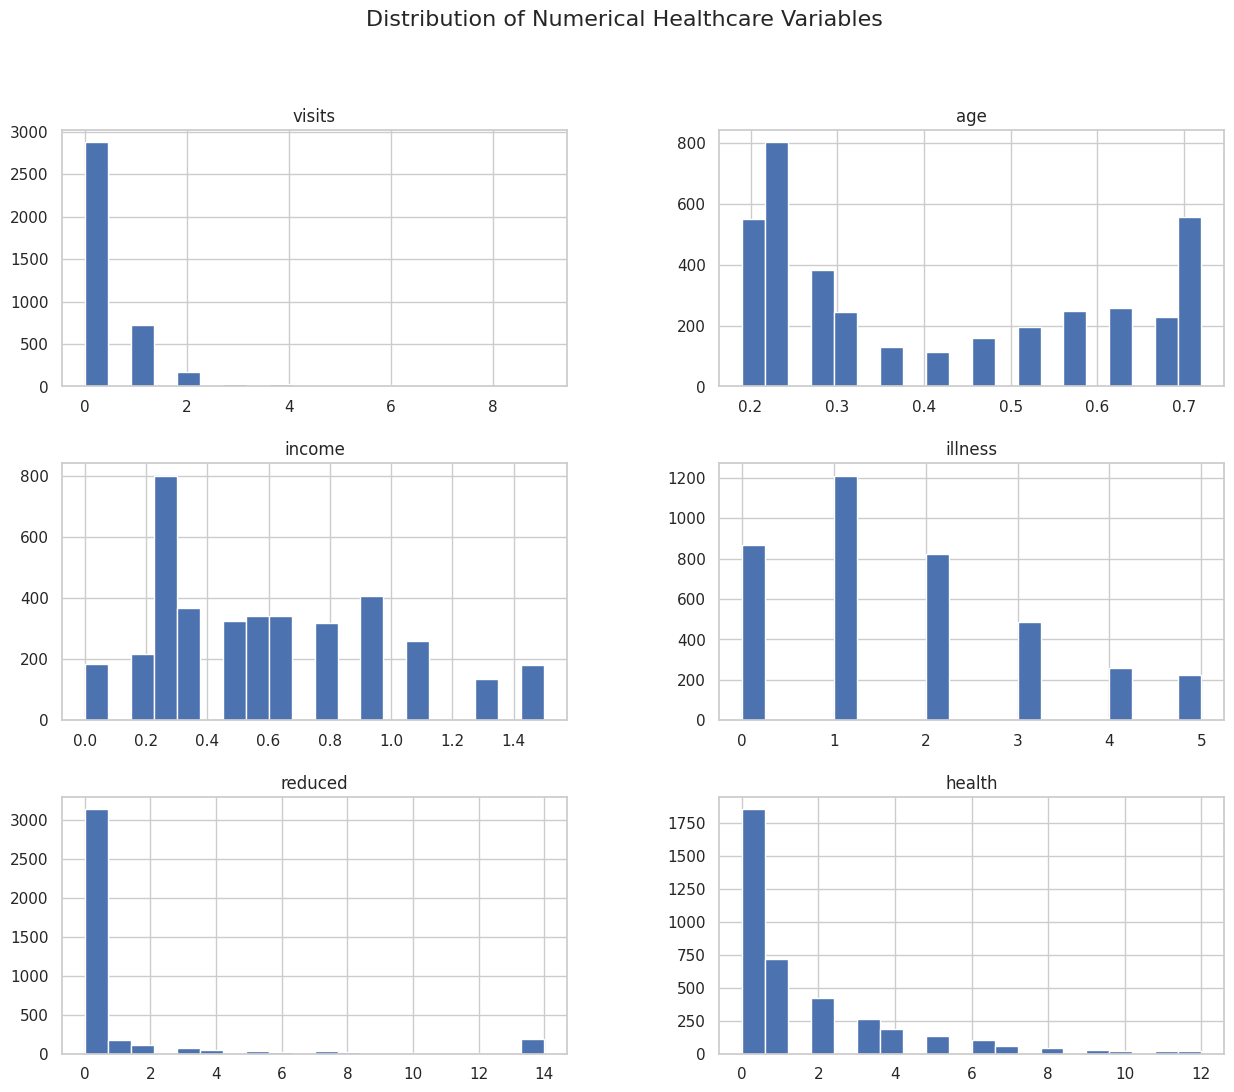

In [83]:
numeric_columns = [
    'visits',
    'age',
    'income',
    'illness',
    'reduced',
    'health'
]

df[numeric_columns].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Healthcare Variables",
    fontsize=16
)

plt.show()

**Boxplots for All Numerical Variables**

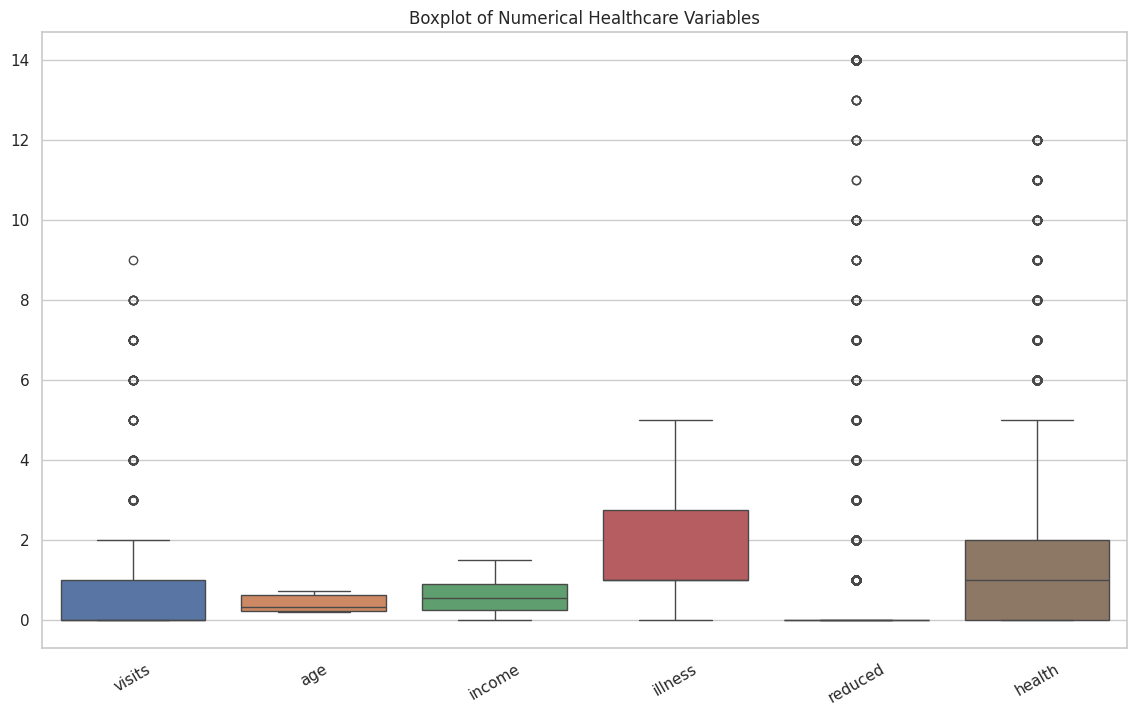

In [84]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df[numeric_columns]
)

plt.title("Boxplot of Numerical Healthcare Variables")
plt.xticks(rotation=30)

plt.show()

**Standardized Numerical Heatmap**

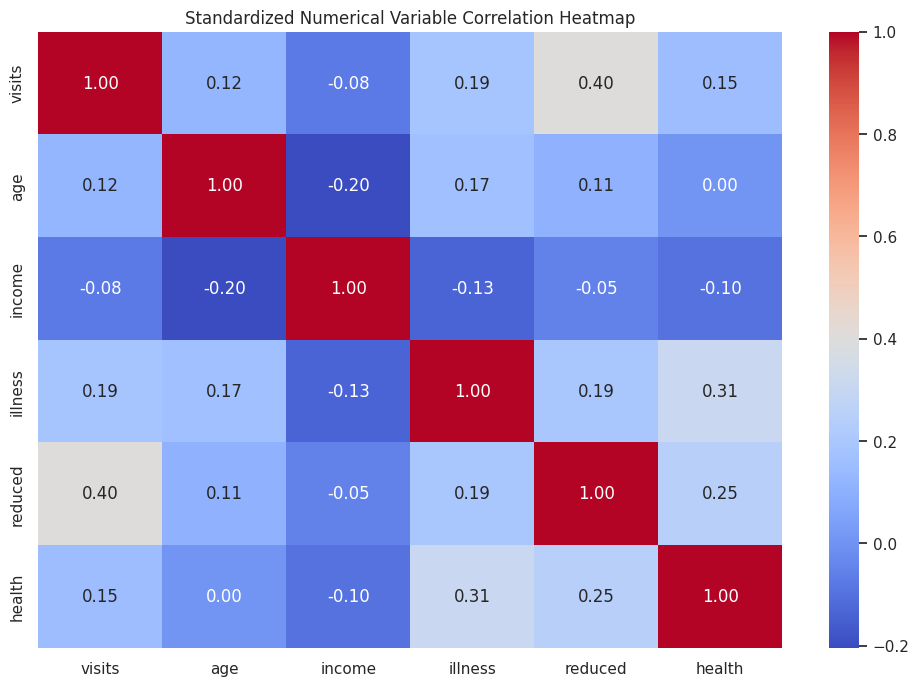

In [85]:
from sklearn.preprocessing import StandardScaler

scaled_data = StandardScaler().fit_transform(
    df[numeric_columns]
)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=numeric_columns
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    scaled_df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("Standardized Numerical Variable Correlation Heatmap")

plt.show()

**Complete Healthcare Correlation Heatmap**

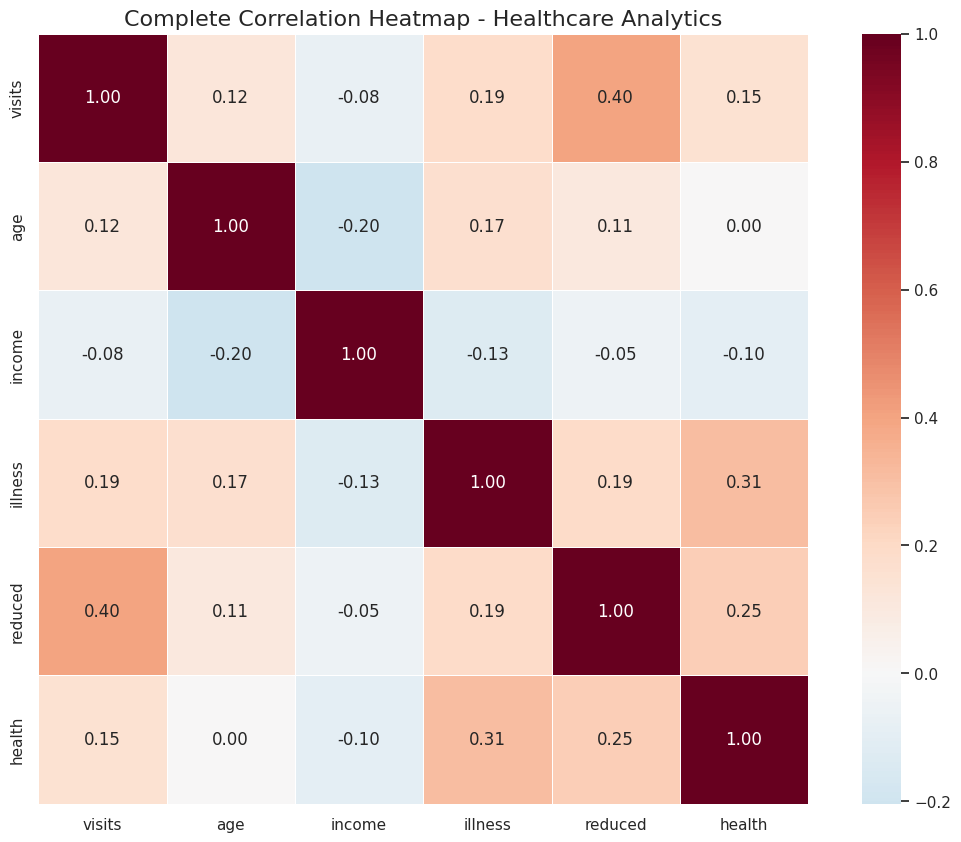

In [86]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Complete Correlation Heatmap - Healthcare Analytics",
    fontsize=16
)

plt.show()

**Strong Correlations**

In [87]:
corr_matrix = df.select_dtypes(
    include=np.number
).corr()

strong_correlations = []

for col1 in corr_matrix.columns:
    for col2 in corr_matrix.columns:
        if col1 != col2:
            correlation_value = corr_matrix.loc[col1, col2]

            if abs(correlation_value) >= 0.30:
                strong_correlations.append(
                    (col1, col2, correlation_value)
                )

strong_correlations

[('visits', 'reduced', np.float64(0.40321266857095905)),
 ('illness', 'health', np.float64(0.3095730371174729)),
 ('reduced', 'visits', np.float64(0.40321266857095905)),
 ('health', 'illness', np.float64(0.3095730371174729))]

**Automated EDA Summary**

In [88]:
print("=" * 60)
print("HEALTHCARE DATASET ANALYSIS")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nAverage Doctor Visits:")
print(df['visits'].mean())

print("\nMedian Doctor Visits:")
print(df['visits'].median())

print("\nMaximum Doctor Visits:")
print(df['visits'].max())

print("\nAverage Age:")
print(df['age'].mean())

print("\nAverage Income:")
print(df['income'].mean())

print("\nAverage Illness:")
print(df['illness'].mean())

print("\nAverage Reduced Activity:")
print(df['reduced'].mean())

print("\nAverage Health:")
print(df['health'].mean())

HEALTHCARE DATASET ANALYSIS

Dataset Shape:
(3870, 15)

Missing Values:
644

Duplicate Rows:
0

Average Doctor Visits:
0.3891472868217054

Median Doctor Visits:
0.0

Maximum Doctor Visits:
9

Average Age:
0.4107622739018088

Average Income:
0.5825503875968993

Average Illness:
1.6705426356589148

Average Reduced Activity:
1.1516795865633076

Average Health:
1.5777777777777777


**Automated Gender Analysis**

In [89]:
gender_analysis = df.groupby('gender').agg(
    Patients=('gender', 'count'),
    Avg_Visits=('visits', 'mean'),
    Avg_Age=('age', 'mean'),
    Avg_Income=('income', 'mean'),
    Avg_Illness=('illness', 'mean'),
    Avg_Reduced=('reduced', 'mean'),
    Avg_Health=('health', 'mean')
).round(2)

gender_analysis

,Patients,Avg_Visits,Avg_Age,Avg_Income,Avg_Illness,Avg_Reduced,Avg_Health
gender,,,,,,,
female,2068,0.45,0.45,0.50,1.81,1.27,1.69
male,1802,0.32,0.37,0.67,1.52,1.02,1.45


**Automated Healthcare Profile**

In [90]:
healthcare_profile = df.groupby('health').agg(
    Patients=('health', 'count'),
    Avg_Visits=('visits', 'mean'),
    Avg_Age=('age', 'mean'),
    Avg_Income=('income', 'mean'),
    Avg_Illness=('illness', 'mean'),
    Avg_Reduced=('reduced', 'mean')
).round(2)

healthcare_profile

,Patients,Avg_Visits,Avg_Age,Avg_Income,Avg_Illness,Avg_Reduced
health,,,,,,
0,1851,0.30,0.41,0.61,1.26,0.52
1,719,0.37,0.41,0.59,1.68,1.23
2,419,0.40,0.40,0.54,1.96,1.44
3,264,0.42,0.40,0.59,2.28,1.36
4,185,0.54,0.42,0.55,2.06,1.81
5,132,0.53,0.41,0.52,2.42,1.59
6,102,0.64,0.40,0.49,2.44,3.13
7,61,0.92,0.46,0.47,2.70,4.10
8,41,0.49,0.41,0.48,2.49,2.88
